In [1]:
# Local setup: select the torch3_clean Python environment as the notebook kernel.
# No code/data downloads or automatic package installations are performed.
import os
import sys
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

# Works when the notebook kernel starts in pcb/ or the repository root.
code_candidates = [Path.cwd(), Path.cwd() / "pcb"]
CODE_DIR = next((p.resolve() for p in code_candidates
                 if (p / "nn_unet.py").is_file() and (p / "dataset.py").is_file()), None)
if CODE_DIR is None:
    raise FileNotFoundError("Start the notebook from pcb/ or the Surrogates repository root.")
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

# Prefer the dataset beside pcb/, with support for the existing pcb/data/ clone.
# Set PCB_DATA_ROOT to override either location, e.g. for a sample-only check.
data_override = os.environ.get("PCB_DATA_ROOT")
data_candidates = ([Path(data_override)] if data_override else [
    CODE_DIR.parent / "Multi-topology-Dataset",
    CODE_DIR.parent / "data" / "Multi-topology-Dataset",
    CODE_DIR / "data" / "Multi-topology-Dataset",
])
DATA_ROOT = next((p.resolve() for p in data_candidates
                  if all((p / split).is_dir() for split in ("TrainData", "ValData"))), None)
if DATA_ROOT is None:
    raise FileNotFoundError(f"Expected TrainData/ValData under one of: {data_candidates}")

WORKING_DIR = Path(os.environ.get("PCB_WORKING_DIR", str(CODE_DIR / "outputs" / "patch_context_global_local_1000pairs")))
WORKING_DIR.mkdir(parents=True, exist_ok=True)
SMOKE_TEST = os.environ.get("PCB_SMOKE_TEST", "0") == "1"

requirements = {"nnunetv2": "2.7.0", "dynamic-network-architectures": "0.4.3"}
try:
    installed = {name: version(name) for name in requirements}
except PackageNotFoundError as exc:
    raise ModuleNotFoundError(
        "Select torch3_clean, or install the dependencies in the current kernel with "
        "%pip install nnunetv2==2.7.0 dynamic-network-architectures==0.4.3 h5py pandas matplotlib"
    ) from exc
print("Python:", sys.executable)
print("Local code:", CODE_DIR)
print("Local dataset:", DATA_ROOT)
print("Outputs:", WORKING_DIR)
print("External packages:", installed)
print("Smoke-test configuration:", SMOKE_TEST)


Python: <user-profile>\AppData\Local\miniconda3\envs\torch3_clean\python.exe
Local code: pcb
Local dataset: pcb\data\Multi-topology-Dataset
Outputs: pcb\outputs\patch_context_global_local_1000pairs
External packages: {'nnunetv2': '2.7.0', 'dynamic-network-architectures': '0.4.3'}
Smoke-test configuration: False


In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from pathlib import Path
import json
import time
from dataset import PCBDataset, NormalizationStats
from nn_unet import PCBImageDataset
from nn_unet_global_context import GlobalContextNNUNetRegressor, GlobalContextPatchDataset
from patch_context_experiment import (
    build_matched_subset, split_pairs, MatchedPatchDataset, plot_pair, read_case,
)
from IPython.display import display
from importlib.metadata import version
PACKAGE_VERSIONS = {name: version(name) for name in ("nnunetv2", "dynamic-network-architectures")}
print("External packages:", PACKAGE_VERSIONS)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
External packages: {'nnunetv2': '2.7.0', 'dynamic-network-architectures': '0.4.3'}


## 1. Hyperparameters

In [3]:
HPARAMS = {
    # controlled subset: TrainData only; multiple matched condition pairs per geometry
    "data_root": str(DATA_ROOT),
    "n_pairs": 1000,  # verified condition pairs, not 1000 distinct layouts
    "pairs_per_layout": 3,  # one pair per layout first, then second/third pairs
    "validation_fraction": 0.2,  # split by distinct geometry
    "max_layouts_to_check": None,  # examine every TrainData layout
    "patch_size": 64,
    "unchanged_margin": 16,  # no changed power within this halo around the patch
    "inspect_pairs": 3,  # only a few detailed previews; overview covers all pairs
    "run_test": False,

    # whole-board coarse encoder + local residual U-Net; patch-only output
    "architecture": "resenc",
    "n_blocks_per_stage": [1, 1, 1, 1, 1],  # two main-path convolutions per residual block
    "input_channels": 8,
    "out_channels": 1,
    "features_per_stage": [32, 64, 128, 256, 320],
    "global_size": 64,  # entire board, not a local crop
    "global_attention_heads": 4,  # all-to-all mixing before ROI sampling
    "n_conv_per_stage": 2,  # used by plain mode; resenc uses n_blocks_per_stage
    "n_conv_per_stage_decoder": 2,

    # train on both fixed 64x64 targets from every training pair, no augmentation
    "batch_size": 32,
    "epochs": 200,
    "lr": 1e-3,
    "weight_decay": 0.0,
    "max_grad_norm": 0.1,

    # runtime
    "num_workers": 0,
    "pin_memory": True,
    "seed": 42,

    # output
    "checkpoint_path": str(WORKING_DIR / "patch_context.pt"),
    "last_checkpoint_path": str(WORKING_DIR / "patch_context_last.pt"),
    "debug_csv_path": str(WORKING_DIR / "patch_context_debug_log.csv"),
}

DEBUG = {
    "stop_on_nonfinite": True,
    "log_every_n_batches": 20,
    "print_every_n_batches": 20,
    "max_train_batches": None,
    "max_eval_batches": None,
    "detect_anomaly": False,
    "save_parameter_snapshots": True,
}
if SMOKE_TEST:
    HPARAMS.update(features_per_stage=[8, 16, 32], n_blocks_per_stage=[1, 1, 1],
                   epochs=1, batch_size=4, inspect_pairs=2)
    torch.set_num_threads(2)
torch.autograd.set_detect_anomaly(DEBUG["detect_anomaly"])


## 2. Diagnostics

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def tensor_stats(x):
    x = x.detach()
    finite = torch.isfinite(x)

    out = {
        "finite_fraction": finite.float().mean().item(),
        "nan_count": torch.isnan(x).sum().item(),
        "inf_count": torch.isinf(x).sum().item(),
    }

    if finite.any():
        xf = x[finite].float()
        out.update({
            "mean": xf.mean().item(),
            "std": xf.std(unbiased=False).item(),
            "rms": torch.sqrt(torch.mean(xf * xf)).item(),
            "absmax": xf.abs().max().item(),
            "norm": xf.norm().item(),
            "min": xf.min().item(),
            "max": xf.max().item(),
        })
    else:
        out.update({
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
            "min": np.nan, "max": np.nan,
        })

    return out


def check_finite(name, x, context=None):
    if torch.isfinite(x).all():
        return

    context = context or {}
    print("\n" + "=" * 90)
    print("NON-FINITE TENSOR:", name)
    print("context:", context)
    print("shape:", tuple(x.shape))
    print("stats:", tensor_stats(x))
    print("=" * 90)

    if DEBUG["stop_on_nonfinite"]:
        raise FloatingPointError(f"{name} contains NaN/Inf at {context}")


def flatten_finite_tensors(tensors):
    vals = []
    for t in tensors:
        if t is None:
            continue
        a = t.detach().float().reshape(-1).cpu()
        a = a[torch.isfinite(a)]
        if a.numel():
            vals.append(a)
    return torch.cat(vals) if vals else torch.empty(0)


def parameter_group_map(model):
    # named_parameters deduplicates the upstream decoder's encoder references.
    named = list(model.named_parameters())
    groups = {
        "input_encoder": [p for name, p in named if name.startswith("network.encoder.stages.0.")],
        "blocks": [p for name, p in named if name.startswith("network.encoder.")
                   and not name.startswith("network.encoder.stages.0.")],
        "decoder": [p for name, p in named if name.startswith("network.decoder.")],
        "global_encoder": [p for name, p in named if name.startswith("global_encoder.")],
        "context_fusion": [p for name, p in named
                           if name.startswith(("global_norm.", "global_attention.", "global_ff_norm.",
                                               "global_ff.", "context_fusion."))],
    }
    grouped = [id(p) for values in groups.values() for p in values]
    assert len(grouped) == len(set(grouped)) == len(named), "Parameter groups must partition the model"
    return groups


def stats_from_flat(flat):
    if flat.numel() == 0:
        return {
            "mean": np.nan, "std": np.nan, "rms": np.nan,
            "absmax": np.nan, "norm": np.nan,
        }
    return {
        "mean": flat.mean().item(),
        "std": flat.std(unbiased=False).item(),
        "rms": torch.sqrt(torch.mean(flat * flat)).item(),
        "absmax": flat.abs().max().item(),
        "norm": flat.norm().item(),
    }


def group_parameter_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.data for p in params])
    )


def group_gradient_stats(params):
    return stats_from_flat(
        flatten_finite_tensors([p.grad for p in params if p.grad is not None])
    )


def snapshot_parameter_values(model):
    return {
        name: flatten_finite_tensors([p.data for p in params]).numpy()
        for name, params in parameter_group_map(model).items()
    }


def snapshot_gradient_values(model):
    return {
        name: flatten_finite_tensors(
            [p.grad for p in params if p.grad is not None]
        ).numpy()
        for name, params in parameter_group_map(model).items()
    }


set_seed(HPARAMS["seed"])

## 3. Build the controlled subset and inspect representative pairs

The selection uses only original `TrainData`. Each pair has the same layout, masks, instance map and cooling, with exactly one changed power-setting parameter. The fixed patch has identical power and other inputs, and no changed power within the configured surrounding margin. The patch location maximizes unchanged locally powered pixels, without ranking by temperature differences. Both members of a pair stay in the same split, with distinct layouts held out for investigation validation. This is an investigation-specific split, not the original ValData/TestData benchmark.

The following cell saves the pair manifest and plots the selected cases **before the model is instantiated**. Inspect the red patch rectangles, external power changes and the two local temperature targets.
The new model additionally receives all eight full-board input channels area-averaged to 64x64. Both branches use [32,64,128,256,320] channels. The coarse encoder mixes all bottleneck locations with self-attention before sampling features at the requested patch. There is no coarse temperature target or full-board temperature prediction. The additional preview shows that global power inputs differ while local inputs remain identical.


Building verified matched simulation pairs...
Examined 25/424 layouts; verified 75 candidate pairs
Examined 50/424 layouts; verified 150 candidate pairs
Examined 75/424 layouts; verified 225 candidate pairs
Examined 100/424 layouts; verified 300 candidate pairs
Examined 125/424 layouts; verified 375 candidate pairs
Examined 150/424 layouts; verified 450 candidate pairs
Examined 175/424 layouts; verified 525 candidate pairs
Examined 200/424 layouts; verified 600 candidate pairs
Examined 225/424 layouts; verified 675 candidate pairs
Examined 250/424 layouts; verified 750 candidate pairs
Examined 275/424 layouts; verified 825 candidate pairs
Examined 300/424 layouts; verified 900 candidate pairs
Examined 325/424 layouts; verified 975 candidate pairs
Examined 350/424 layouts; verified 1050 candidate pairs
Examined 375/424 layouts; verified 1125 candidate pairs
Examined 400/424 layouts; verified 1200 candidate pairs
Selected 1000 verified pairs across 424 geometries


,pair_id,subset,topology,mask_id,h_value,Pigbt_a,Pigbt_b,Pfwd_a,Pfwd_b,row,column,valid_powered_patch_locations,local_inputs_identical,target_difference_rel_l2,unavoidable_worst_case_rel_l2
0,0,val,Mask_3P6P_V1,000,2000,150,150,100,150,141,87,9304,True,0.109320,0.051876
1,1,train,Mask_3P6P_V2,000,2000,150,150,100,150,44,110,11440,True,0.096586,0.046085
2,2,val,Mask_HB_V1,000,2000,150,150,150,200,68,91,6374,True,0.075723,0.036490
3,3,train,Mask_HB_V2,000,2000,150,150,100,150,41,55,8586,True,0.093300,0.044576
4,4,train,Mask_HB_V3-0,000,2000,150,150,100,200,88,119,3683,True,0.252311,0.112080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,995,val,Mask_3P6P_V2,024,2000,350,350,100,150,32,35,10235,True,0.054237,0.026405
996,996,train,Mask_HB_V2,029,2000,350,350,100,150,46,140,7896,True,0.064775,0.031394
997,997,train,Mask_HB_V3-0,035,2000,150,350,100,100,8,34,1679,True,0.465438,0.188827
998,998,val,Mask_HB_V3-1,028,2000,350,350,100,150,53,53,7558,True,0.058783,0.028557


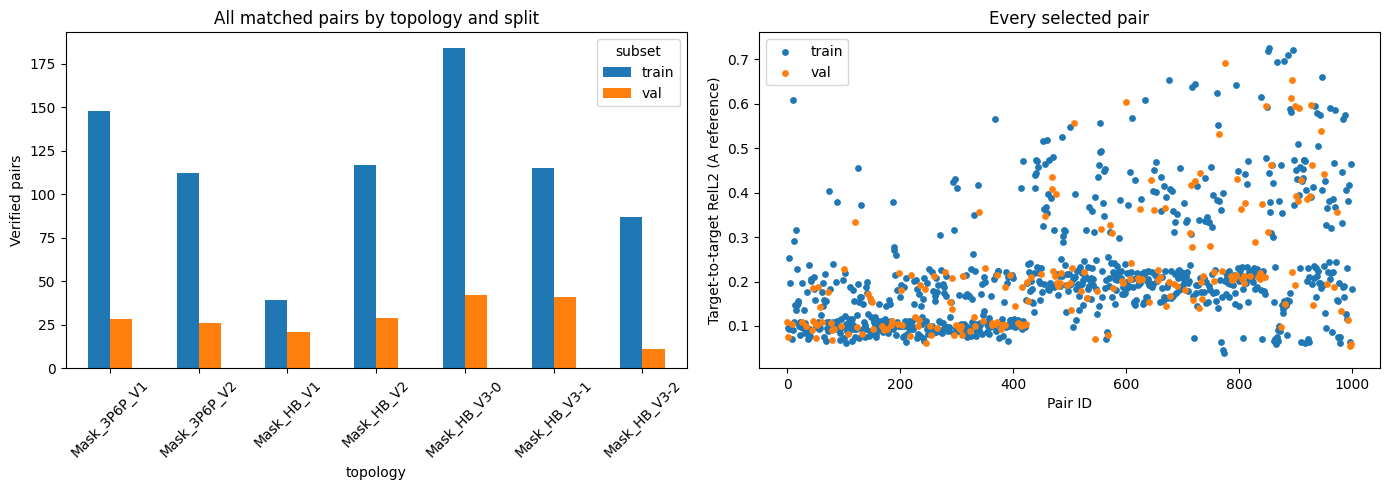

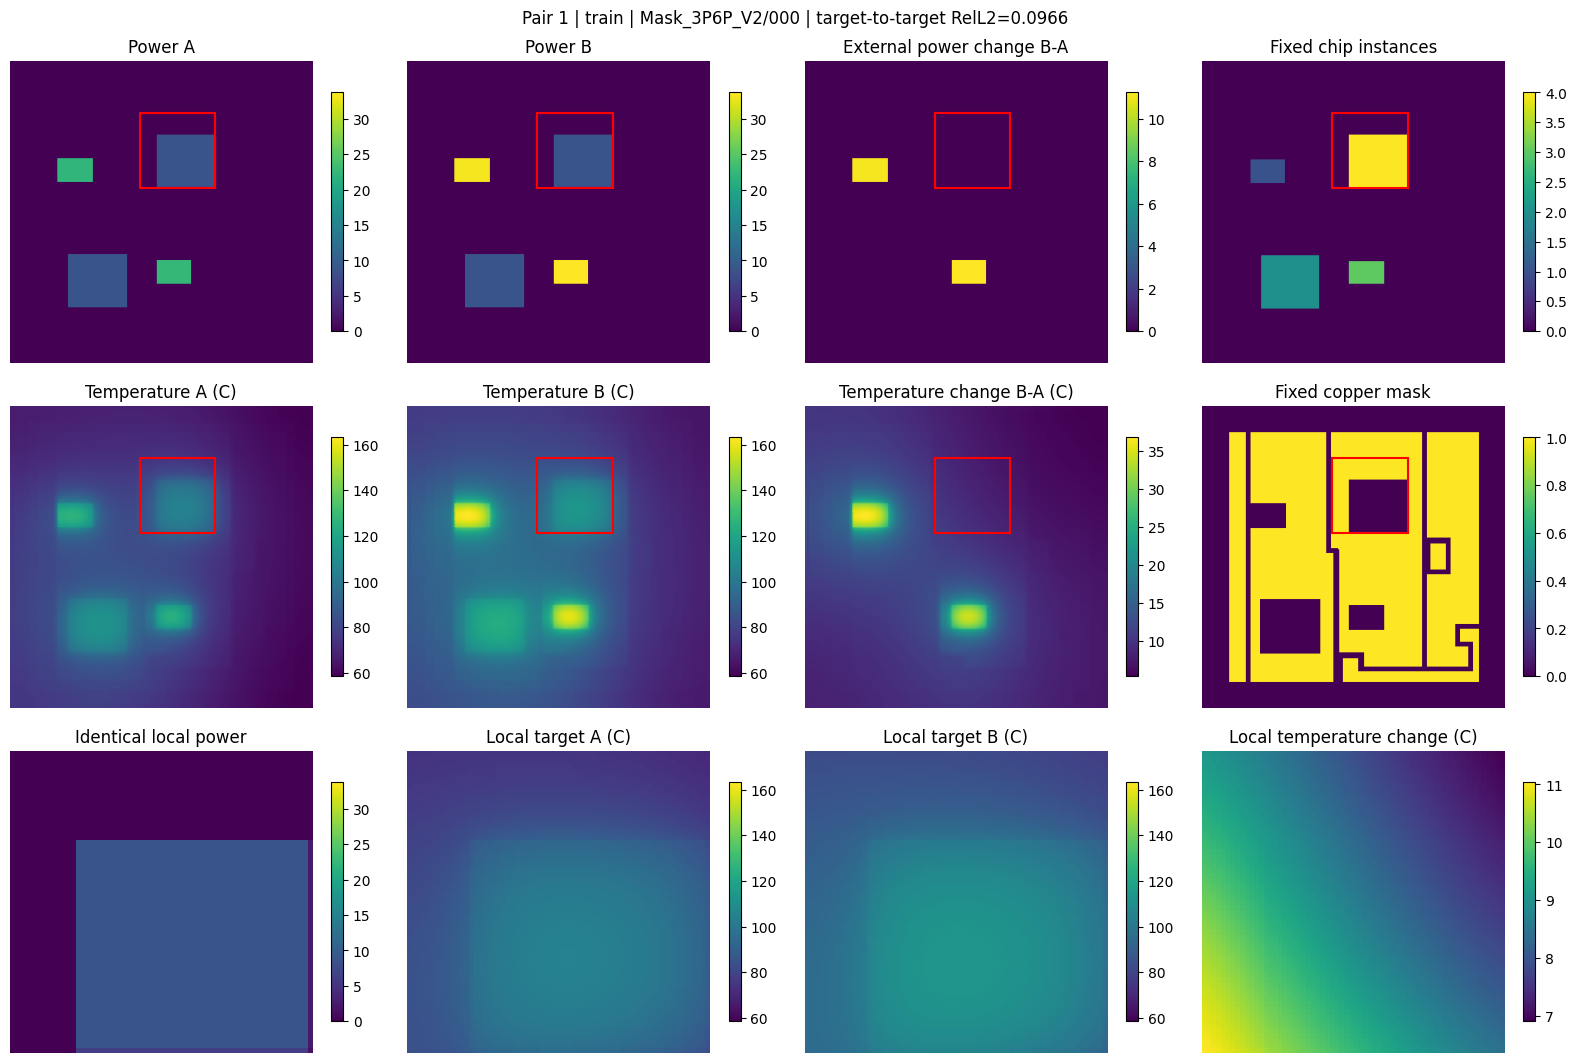

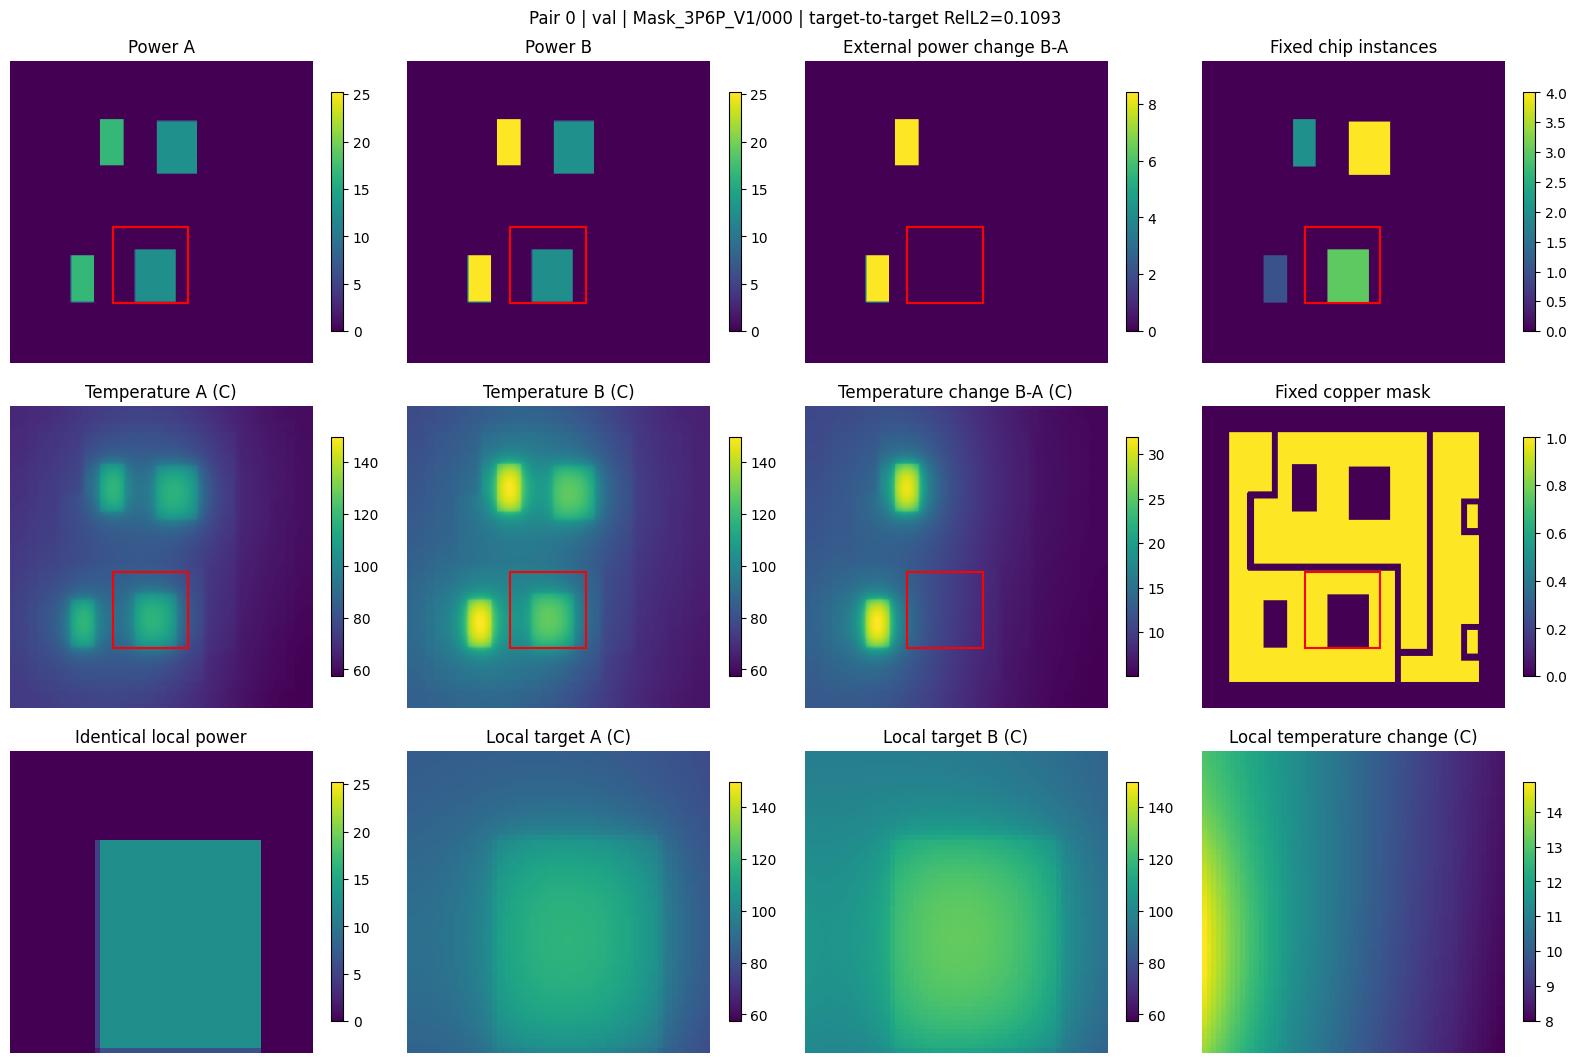

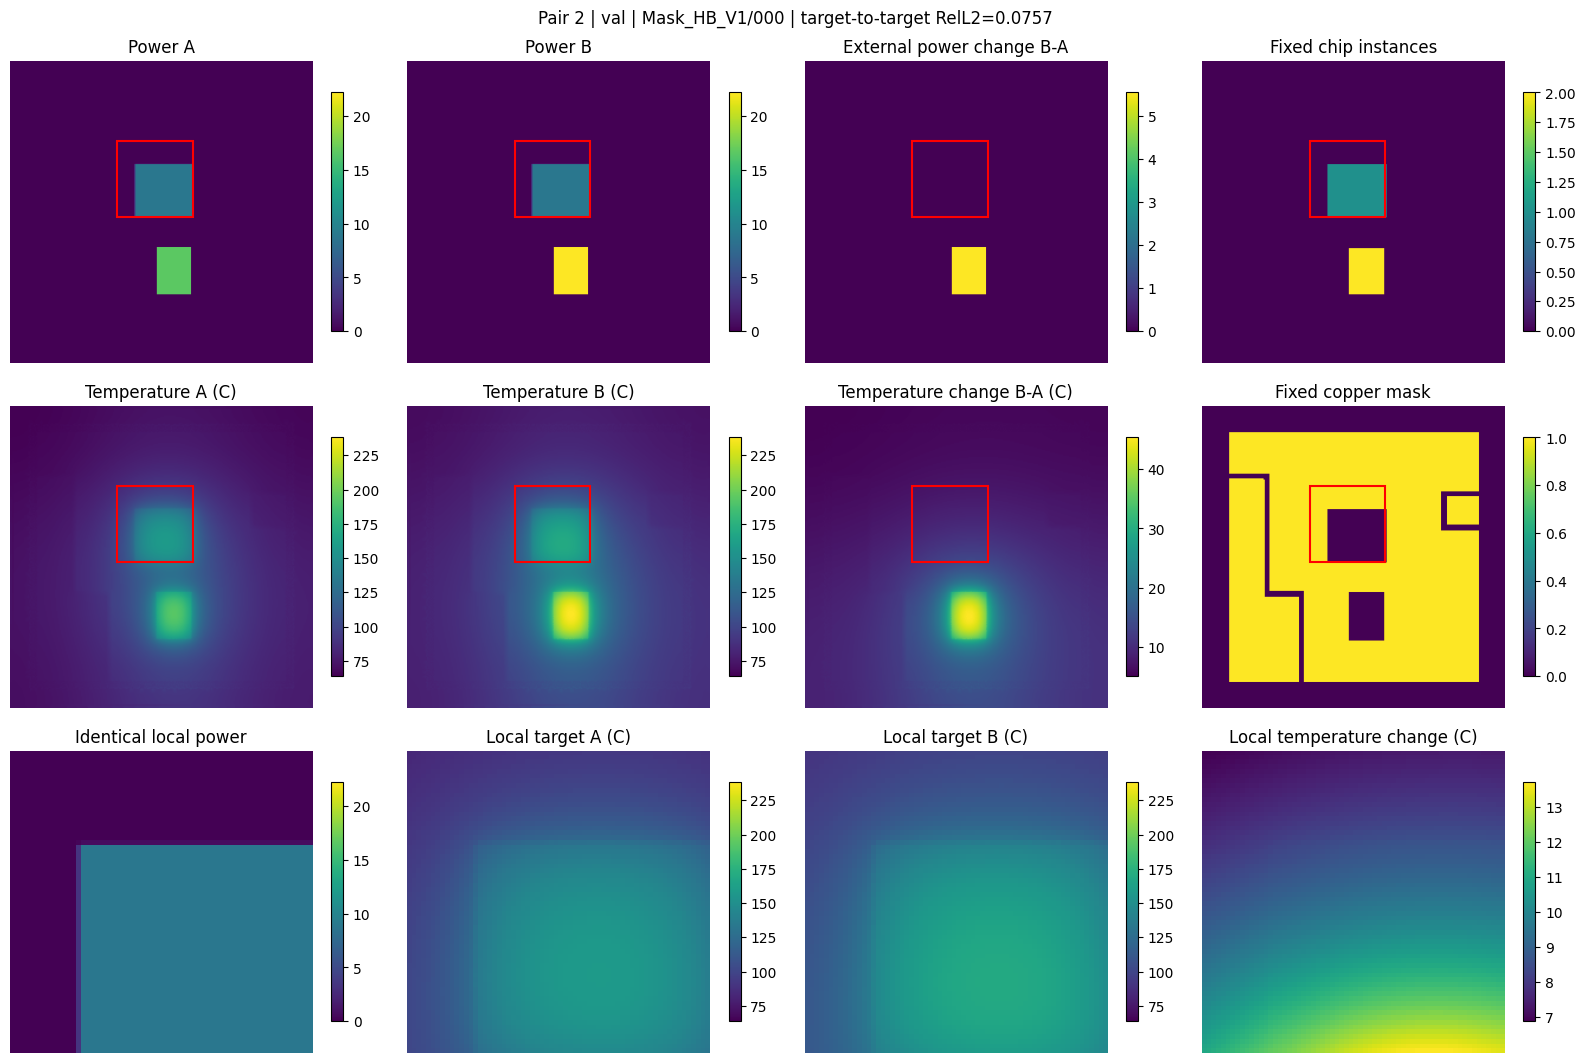

Fitting normalization on 1153 training files...
Normalization: 25/1153 files, 0.1s
Normalization: 50/1153 files, 0.1s
Normalization: 75/1153 files, 0.2s
Normalization: 100/1153 files, 0.2s
Normalization: 125/1153 files, 0.3s
Normalization: 150/1153 files, 0.4s
Normalization: 175/1153 files, 0.5s
Normalization: 200/1153 files, 0.5s
Normalization: 225/1153 files, 0.6s
Normalization: 250/1153 files, 0.7s
Normalization: 275/1153 files, 0.8s
Normalization: 300/1153 files, 0.8s
Normalization: 325/1153 files, 0.9s
Normalization: 350/1153 files, 1.0s
Normalization: 375/1153 files, 1.0s
Normalization: 400/1153 files, 1.1s
Normalization: 425/1153 files, 1.2s
Normalization: 450/1153 files, 1.2s
Normalization: 475/1153 files, 1.3s
Normalization: 500/1153 files, 1.4s
Normalization: 525/1153 files, 1.5s
Normalization: 550/1153 files, 1.5s
Normalization: 575/1153 files, 1.6s
Normalization: 600/1153 files, 1.7s
Normalization: 625/1153 files, 1.7s
Normalization: 650/1153 files, 1.8s
Normalization: 675/

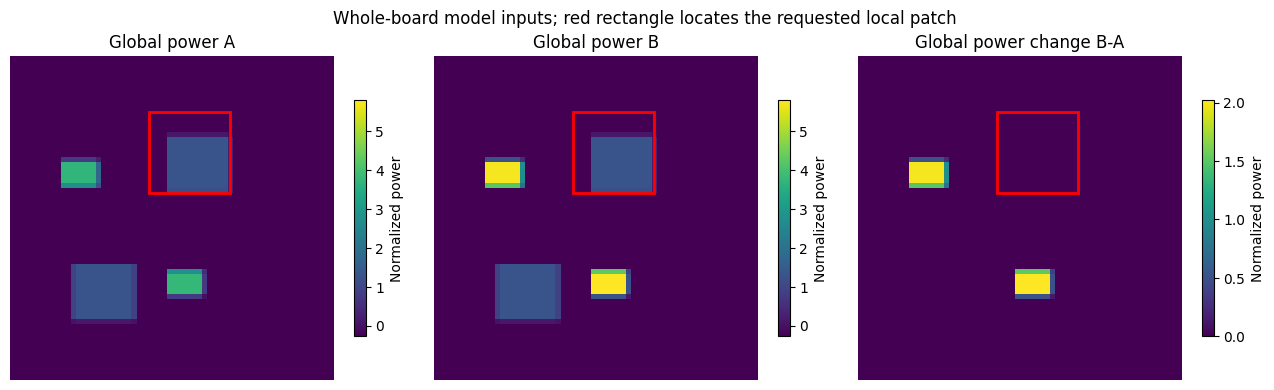

In [5]:
print("Building verified matched simulation pairs...", flush=True)
pairs = build_matched_subset(
    DATA_ROOT, n_pairs=HPARAMS["n_pairs"], patch_size=HPARAMS["patch_size"],
    margin=HPARAMS["unchanged_margin"], max_layouts=HPARAMS["max_layouts_to_check"],
    pairs_per_layout=HPARAMS["pairs_per_layout"],
)
if not 0 < HPARAMS["validation_fraction"] < 1:
    raise ValueError("validation_fraction must be in (0, 1)")
n_geometries = len({r["geometry_hash"] for r in pairs})
n_val_geometries = max(1, min(n_geometries - 1, round(n_geometries * HPARAMS["validation_fraction"])))
pairs = split_pairs(pairs, n_val=n_val_geometries, seed=HPARAMS["seed"])
(WORKING_DIR / "selected_pairs.json").write_text(json.dumps(pairs, indent=2))
pair_table = pd.DataFrame(pairs)
pair_table.to_csv(WORKING_DIR / "selected_pairs.csv", index=False)
display(pair_table[["pair_id", "subset", "topology", "mask_id", "h_value",
                    "Pigbt_a", "Pigbt_b", "Pfwd_a", "Pfwd_b", "row", "column",
                    "valid_powered_patch_locations", "local_inputs_identical",
                    "target_difference_rel_l2", "unavoidable_worst_case_rel_l2"]])

# Summaries cover all verified pairs, not only the detailed previews below.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pd.crosstab(pair_table["topology"], pair_table["subset"]).plot.bar(ax=axes[0])
axes[0].set_title("All matched pairs by topology and split")
axes[0].set_ylabel("Verified pairs"); axes[0].tick_params(axis="x", labelrotation=45)
for subset in ("train", "val"):
    rows = pair_table[pair_table["subset"] == subset]
    axes[1].scatter(rows["pair_id"], rows["target_difference_rel_l2"], s=15, label=subset)
axes[1].set_xlabel("Pair ID"); axes[1].set_ylabel("Target-to-target RelL2 (A reference)")
axes[1].set_title("Every selected pair"); axes[1].legend()
fig.tight_layout(); fig.savefig(WORKING_DIR / "all_pairs_overview.png", dpi=140)
plt.show(); plt.close(fig)

# Inspection comes before normalization, loaders, model creation and training.
# Include both training and validation in the small preview selection.
preview_order = [next(r for r in pairs if r["subset"] == subset) for subset in ("train", "val")]
preview_order += [r for r in pairs if r["pair_id"] not in {p["pair_id"] for p in preview_order}]
preview_pairs = preview_order[:HPARAMS["inspect_pairs"]]
preview_pair_ids = {r["pair_id"] for r in preview_pairs}
for record in preview_pairs:
    fig = plot_pair(DATA_ROOT, record)
    fig.savefig(WORKING_DIR / f"inspect_pair_{record['pair_id']:02d}.png", dpi=130)
    plt.show()
    plt.close(fig)

train_pairs = [r for r in pairs if r["subset"] == "train"]
val_pairs = [r for r in pairs if r["subset"] == "val"]
assert not ({r["geometry_hash"] for r in train_pairs}
            & {r["geometry_hash"] for r in val_pairs})
train_files = sorted({DATA_ROOT / r[key] for r in train_pairs for key in ("path_a", "path_b")})
normalizer = NormalizationStats.fit(
    train_files, cache_path=WORKING_DIR / "pcb_normalization.json", progress_every=25,
)
train_dataset = GlobalContextPatchDataset(DATA_ROOT, train_pairs, normalizer, global_size=HPARAMS["global_size"])
val_dataset = GlobalContextPatchDataset(DATA_ROOT, val_pairs, normalizer, global_size=HPARAMS["global_size"])
train_loader = DataLoader(train_dataset, batch_size=HPARAMS["batch_size"], shuffle=True,
                          num_workers=HPARAMS["num_workers"], pin_memory=HPARAMS["pin_memory"])
val_loader = DataLoader(val_dataset, batch_size=HPARAMS["batch_size"], shuffle=False,
                        num_workers=HPARAMS["num_workers"], pin_memory=HPARAMS["pin_memory"])
test_dataset = test_loader = None
print("Training geometries / pairs / unique patches:", len({r["geometry_hash"] for r in train_pairs}), len(train_pairs), len(train_dataset))
print("Validation geometries / pairs / unique patches:", len({r["geometry_hash"] for r in val_pairs}), len(val_pairs), len(val_dataset))
print("Training batches per epoch:", len(train_loader))
example_inputs, example_target = train_dataset[0]
print("Model inputs:", {key: tuple(value.shape) for key, value in example_inputs.items()})
print("Patch target:", tuple(example_target.shape))
print("Local inputs match EXACTLY within each pair; whole-board coarse inputs differ.")
print("Tests disabled. No random crops, augmentation, case IDs or power-setting labels enter the model.")

# Preview the actual whole-board power channel supplied to the model.
from matplotlib.patches import Rectangle
record = preview_pairs[0]
preview_dataset = train_dataset if record["subset"] == "train" else val_dataset
pair_index = next(i for i, r in enumerate(preview_dataset.records) if r["pair_id"] == record["pair_id"])
idx_a, idx_b = preview_dataset.pair_indices[pair_index]
inputs_a, _ = preview_dataset[idx_a]
inputs_b, _ = preview_dataset[idx_b]
assert torch.equal(inputs_a["local"], inputs_b["local"])
assert not torch.equal(inputs_a["global"], inputs_b["global"])
a, b = inputs_a["global"][2].numpy(), inputs_b["global"][2].numpy()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for j, (ax, array, title) in enumerate(zip(axes, (a, b, b-a),
                            ("Global power A", "Global power B", "Global power change B-A"))):
    options = {"vmin": min(a.min(), b.min()), "vmax": max(a.max(), b.max())} if j < 2 else {}
    im = ax.imshow(array, **options)
    left, top, right, bottom = inputs_a["roi"].numpy() * HPARAMS["global_size"]
    ax.add_patch(Rectangle((left-.5, top-.5), right-left, bottom-top,
                           fill=False, edgecolor="red", linewidth=2))
    ax.set_title(title); ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=.7, label="Normalized power")
fig.suptitle("Whole-board model inputs; red rectangle locates the requested local patch")
fig.tight_layout(); fig.savefig(WORKING_DIR / "global_context_inputs.png", dpi=140)
plt.show(); plt.close(fig)


## 4. Debug recorder

In [6]:
class DebugRecorder:
    def __init__(self):
        self.rows = []

    def record_tensor(self, tag, x, context):
        row = dict(context)
        row.update({"kind": "tensor", "tag": tag, **tensor_stats(x)})
        self.rows.append(row)

    def record_scalar(self, tag, value, context):
        row = dict(context)
        row.update({"kind": "scalar", "tag": tag, "value": float(value)})
        self.rows.append(row)

    def dataframe(self):
        return pd.DataFrame(self.rows)


recorder = DebugRecorder()

## 5. Global context network and diagnostics hooks


In [7]:
# Encoders and local decoder come from nnU-Net; context mixing and fusion are our adapter.
diagnostic_context = None
hook_handles = []


def stage_hook(name):
    def hook(module, inputs, output):
        if diagnostic_context is not None:
            check_finite(name, output, diagnostic_context)
            recorder.record_tensor(name, output, diagnostic_context)
    return hook


def inputs_to_device(inputs):
    return {key: value.to(device, non_blocking=True) for key, value in inputs.items()}


def predict_field(inputs):
    # Only patch temperature is produced; the coarse board supplies input features.
    return model(inputs_to_device(inputs)).detach().cpu()


## 6. Instantiate model

In [8]:
# Load the exact local file, even if this kernel previously imported an older class.
import importlib.util
import importlib
import nn_unet as nn_unet_module
importlib.reload(nn_unet_module)
model_file = CODE_DIR / "nn_unet_global_context.py"
model_spec = importlib.util.spec_from_file_location("pcb_current_global_context_nn_unet", model_file)
model_module = importlib.util.module_from_spec(model_spec)
model_spec.loader.exec_module(model_module)
GlobalContextNNUNetRegressor = model_module.GlobalContextNNUNetRegressor
print("Loaded model implementation:", model_file)

# Rerunning this cell replaces the model/optimizer and removes old diagnostic hooks.
for handle in hook_handles:
    handle.remove()
hook_handles = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_kwargs = {key: HPARAMS[key] for key in (
    "input_channels", "out_channels", "features_per_stage",
    "n_conv_per_stage", "n_conv_per_stage_decoder", "architecture", "n_blocks_per_stage",
    "global_size", "global_attention_heads")}
model = GlobalContextNNUNetRegressor(**model_kwargs).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=HPARAMS["lr"],
                              weight_decay=HPARAMS["weight_decay"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=HPARAMS["epochs"])

for index, stage in enumerate(model.network.encoder.stages):
    hook_handles.append(stage.register_forward_hook(stage_hook(f"encoder.{index}")))
for index, stage in enumerate(model.network.decoder.stages):
    hook_handles.append(stage.register_forward_hook(stage_hook(f"decoder.{index}")))

for index, stage in enumerate(model.global_encoder.stages):
    hook_handles.append(stage.register_forward_hook(stage_hook(f"global_encoder.{index}")))
hook_handles.append(model.context_fusion.register_forward_hook(stage_hook("context_fusion")))

initial_parameter_snapshot = snapshot_parameter_values(model) if DEBUG["save_parameter_snapshots"] else {}
print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print(model)


Loaded model implementation: pcb\nn_unet_global_context.py
Device: cuda
Parameters: 9825860
GlobalContextNNUNetRegressor(
  (network): ResidualEncoderUNet(
    (encoder): ResidualEncoder(
      (stem): StackedConvBlocks(
        (convs): Sequential(
          (0): ConvDropoutNormReLU(
            (conv): Conv2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm): InstanceNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
            (nonlin): LeakyReLU(negative_slope=0.01, inplace=True)
            (all_modules): Sequential(
              (0): Conv2d(8, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
              (1): InstanceNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
              (2): LeakyReLU(negative_slope=0.01, inplace=True)
            )
          )
        )
      )
      (stages): Sequential(
        (0): StackedResidualBlocks(
          (blocks): Sequential(
            (0): BasicBlockD

## 7. Loss and metric

In [9]:
def relative_l2_per_sample(pred, target):
    B = pred.shape[0]

    pred = pred.reshape(B, -1)
    target = target.reshape(B, -1)

    diff_norm = torch.norm(
        pred - target,
        p=2,
        dim=1,
    )

    target_norm = torch.norm(
        target,
        p=2,
        dim=1,
    )

    return diff_norm / target_norm


def relative_l2_loss(pred, target):
    return relative_l2_per_sample(
        pred,
        target,
    ).sum()


def mae_metric(pred, target):
    return torch.mean(
        torch.abs(pred - target)
    )

class RelativeL2Stats:
    """Exact distribution of the same per-sample RelL2 used by the epoch mean.

    One value per training patch/image or reconstructed validation image.
    Ratios are dimensionless: 0.1 corresponds to 10%, not degrees Celsius.
    """
    def __init__(self):
        self.values = []

    def __enter__(self):
        return self

    def update(self, prediction, target):
        ratios = relative_l2_per_sample(prediction.detach(), target.detach()).float().cpu().numpy()
        if not np.isfinite(ratios).all():
            raise FloatingPointError("Nonfinite per-sample relative L2 errors")
        self.values.append(ratios.copy())

    def result(self):
        if not self.values:
            raise ValueError("No relative L2 errors recorded")
        values = np.concatenate(self.values)
        quantiles = np.percentile(values, [50, 90, 95, 99])
        return dict(zip(
            ("max_rel_l2", "median_rel_l2", "p90_rel_l2", "p95_rel_l2", "p99_rel_l2"),
            [float(values.max()), *map(float, quantiles)],
        ))

    def __exit__(self, *exc):
        self.values.clear()


## 8. Dry run — inspect matched-patch predictions before training

Global-context matched-patch prediction: (32, 1, 64, 64) {'finite_fraction': 1.0, 'nan_count': 0, 'inf_count': 0, 'mean': 99.80975341796875, 'std': 19.965646743774414, 'rms': 101.787109375, 'absmax': 200.42861938476562, 'norm': 36850.88671875, 'min': -55.328834533691406, 'max': 200.42861938476562}
Relative L2: 8.274503707885742
MAE (C): 23.388004302978516


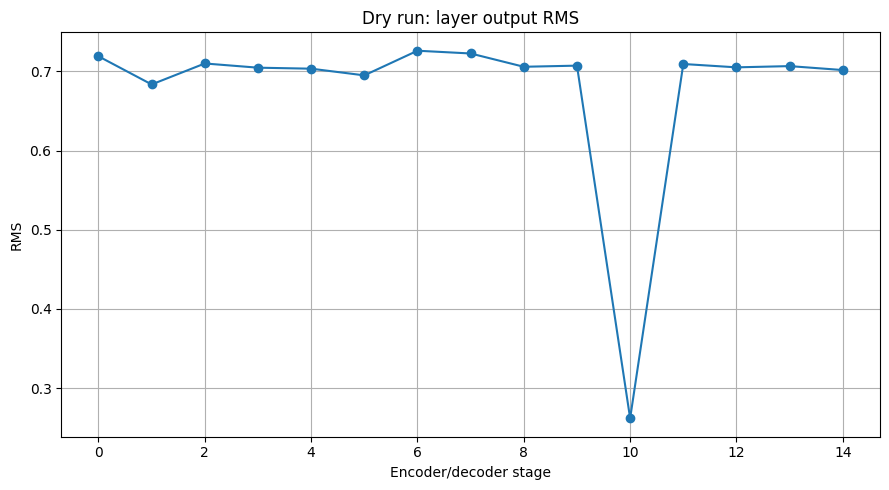

In [10]:
model.eval()
image, target_norm = next(iter(val_loader))
diagnostic_context = {"epoch": 0, "batch": 0, "phase": "dry_run"}
with torch.no_grad():
    pred_norm = predict_field(image)
    pred = normalizer.decode_temperature(pred_norm)
    target = normalizer.decode_temperature(target_norm)
    check_finite("dry_run.prediction", pred, diagnostic_context)
    print("Global-context matched-patch prediction:", tuple(pred.shape), tensor_stats(pred))
    print("Relative L2:", relative_l2_loss(pred, target).item())
    print("MAE (C):", mae_metric(pred, target).item())
diagnostic_context = None
state_rows = recorder.dataframe()
state_rows = state_rows[state_rows["kind"] == "tensor"]
if len(state_rows):
    plt.figure(figsize=(9, 5))
    plt.plot(np.arange(len(state_rows)), state_rows["rms"], marker="o")
    plt.xlabel("Encoder/decoder stage"); plt.ylabel("RMS")
    plt.title("Dry run: layer output RMS"); plt.grid(True); plt.tight_layout(); plt.show()

## 9. Training and evaluation with diagnostics

In [11]:
ERROR_KEYS = ("max_rel_l2", "median_rel_l2", "p90_rel_l2", "p95_rel_l2", "p99_rel_l2")
history = {f"{split}_{metric}": [] for split in ("train", "val")
           for metric in ("rel_l2", "mae", *ERROR_KEYS)}
history["lr"] = []
step_log = []
last_gradient_snapshot = None

def add_group_stats(model, row):
    for group_name, params in parameter_group_map(model).items():
        for prefix, values in (("param", group_parameter_stats(params)),
                               ("grad", group_gradient_stats(params))):
            for key, value in values.items():
                row[f"{prefix}_{group_name}_{key}"] = value

def train_one_epoch_debug(epoch):
    global last_gradient_snapshot, diagnostic_context
    model.train()
    total_rel_l2 = total_mae = total_samples = 0
    with RelativeL2Stats() as error_stats:
        for batch_idx, batch in enumerate(train_loader):
            if DEBUG["max_train_batches"] is not None and batch_idx >= DEBUG["max_train_batches"]:
                break
            image, target_norm = batch
            image = inputs_to_device(image)
            target_norm = target_norm.to(device, non_blocking=True)
            target = normalizer.decode_temperature(target_norm)
            context = {"epoch": epoch, "batch": batch_idx, "phase": "train"}
            detailed = batch_idx % DEBUG["log_every_n_batches"] == 0
            diagnostic_context = context if detailed else None
            optimizer.zero_grad(set_to_none=True)
            pred_norm = model(image)
            diagnostic_context = None
            pred = normalizer.decode_temperature(pred_norm)
            error_stats.update(pred, target)
            loss = relative_l2_loss(pred, target)
            check_finite("train.loss", loss.reshape(1), context)
            loss.backward()
            raw_grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), HPARAMS["max_grad_norm"],
                                                           error_if_nonfinite=True)
            row = dict(context, global_optimizer_step=len(step_log), loss_rel_l2=loss.item(),
                       mae=mae_metric(pred, target).item(), raw_grad_norm=raw_grad_norm.item(),
                       pred_absmax=pred.detach().abs().max().item())
            if detailed:
                add_group_stats(model, row)
                if DEBUG["save_parameter_snapshots"]:
                    last_gradient_snapshot = snapshot_gradient_values(model)
            step_log.append(row)
            optimizer.step()
            for name, parameter in model.named_parameters():
                check_finite("parameter." + name, parameter, context)
            batch_size = image["local"].shape[0]
            total_rel_l2 += relative_l2_per_sample(pred.detach(), target).sum().item()
            total_mae += row["mae"] * batch_size
            total_samples += batch_size
            if batch_idx % DEBUG["print_every_n_batches"] == 0:
                print(f"epoch={epoch:03d} batch={batch_idx:04d} loss={row['loss_rel_l2']:.6g} "
                      f"grad={row['raw_grad_norm']:.3g}")
        if not total_samples:
            raise ValueError("No training batches selected")
        metrics = {"rel_l2": total_rel_l2 / total_samples, "mae": total_mae / total_samples}
        metrics.update(error_stats.result())
        return metrics

@torch.no_grad()
def evaluate_debug(loader):
    model.eval()
    total_rel_l2 = total_mae = total_samples = 0
    with RelativeL2Stats() as error_stats:
        for batch_idx, batch in enumerate(loader):
            if DEBUG["max_eval_batches"] is not None and batch_idx >= DEBUG["max_eval_batches"]:
                break
            image, target_norm = batch  # fixed matched patches, held-out layouts
            target = normalizer.decode_temperature(target_norm)
            pred = normalizer.decode_temperature(predict_field(image))
            check_finite("evaluation.prediction", pred, {"batch": batch_idx})
            error_stats.update(pred, target)
            batch_size = image["local"].shape[0]
            total_rel_l2 += relative_l2_per_sample(pred, target).sum().item()
            total_mae += mae_metric(pred, target).item() * batch_size
            total_samples += batch_size
        if not total_samples:
            raise ValueError("No evaluation batches selected")
        metrics = {"rel_l2": total_rel_l2 / total_samples, "mae": total_mae / total_samples}
        metrics.update(error_stats.result())
        return metrics

## 10. Run training

In [12]:
def format_error_stats(label, metrics):
    return (f"{label} RelL2 distribution: Max {metrics['max_rel_l2']:.6f}, "
            f"Median {metrics['median_rel_l2']:.6f}, P90 {metrics['p90_rel_l2']:.6f}, "
            f"P95 {metrics['p95_rel_l2']:.6f}, P99 {metrics['p99_rel_l2']:.6f}")

training_failed = False
failure_message = None
best_val = float("inf")
try:
    for epoch in range(1, HPARAMS["epochs"] + 1):
        train_metrics = train_one_epoch_debug(epoch)
        val_metrics = evaluate_debug(val_loader)
        # scheduler.step()
        for split, metrics in (("train", train_metrics), ("val", val_metrics)):
            for metric, value in metrics.items():
                history[f"{split}_{metric}"].append(value)
        history["lr"].append(optimizer.param_groups[0]["lr"])
        checkpoint = {"model_class": "GlobalContextNNUNetRegressor", "model_state_dict": model.state_dict(), "model_kwargs": model_kwargs,
                      "controlled_pairs": pairs,
                      "package_versions": PACKAGE_VERSIONS,
                      "optimizer_state_dict": optimizer.state_dict(),
                      "scheduler_state_dict": scheduler.state_dict(), "epoch": epoch,
                      "normalization": normalizer.to_dict(), "hparams": HPARAMS,
                      "history": history, "val_metrics": val_metrics}
        torch.save(checkpoint, HPARAMS["last_checkpoint_path"])
        if val_metrics["rel_l2"] < best_val:
            best_val = val_metrics["rel_l2"]
            torch.save(checkpoint, HPARAMS["checkpoint_path"])
        print(f"\nEpoch {epoch:03d}/{HPARAMS['epochs']} | "
              f"Train RelL2: {train_metrics['rel_l2']:.6f} | Val RelL2: {val_metrics['rel_l2']:.6f} | "
              f"Train MAE: {train_metrics['mae']:.6f} | Val MAE: {val_metrics['mae']:.6f} | "
              f"LR: {optimizer.param_groups[0]['lr']:.3e} | "
              f"{format_error_stats('Train', train_metrics)} | "
              f"{format_error_stats('Val', val_metrics)}\n")
except (FloatingPointError, RuntimeError) as exc:
    training_failed = True
    failure_message = str(exc)
    print("TRAINING STOPPED:", failure_message)
    raise
finally:
    diagnostic_context = None
    step_df = pd.DataFrame(step_log)
    step_df.to_csv(HPARAMS["debug_csv_path"], index=False)
    print("Debug CSV:", HPARAMS["debug_csv_path"])
print("training_failed:", training_failed)

epoch=001 batch=0000 loss=9.72015 grad=15.7
epoch=001 batch=0020 loss=5.44975 grad=3.08
epoch=001 batch=0040 loss=4.38426 grad=2.23

Epoch 001/200 | Train RelL2: 0.166264 | Val RelL2: 0.149269 | Train MAE: 18.992168 | Val MAE: 16.840424 | LR: 1.000e-03 | Train RelL2 distribution: Max 0.628721, Median 0.140823, P90 0.304721, P95 0.370444, P99 0.452528 | Val RelL2 distribution: Max 0.408603, Median 0.129431, P90 0.289200, P95 0.335399, P99 0.385127

epoch=002 batch=0000 loss=5.39642 grad=2.44
epoch=002 batch=0020 loss=5.77401 grad=7.87
epoch=002 batch=0040 loss=5.03756 grad=8.24

Epoch 002/200 | Train RelL2: 0.149852 | Val RelL2: 0.139686 | Train MAE: 17.706657 | Val MAE: 16.312537 | LR: 1.000e-03 | Train RelL2 distribution: Max 0.617176, Median 0.123461, P90 0.293169, P95 0.354773, P99 0.431241 | Val RelL2 distribution: Max 0.402938, Median 0.118030, P90 0.271756, P95 0.326862, P99 0.380705

epoch=003 batch=0000 loss=4.80754 grad=5.29
epoch=003 batch=0020 loss=3.76511 grad=4.2
epoch=003

## 11. Core plots

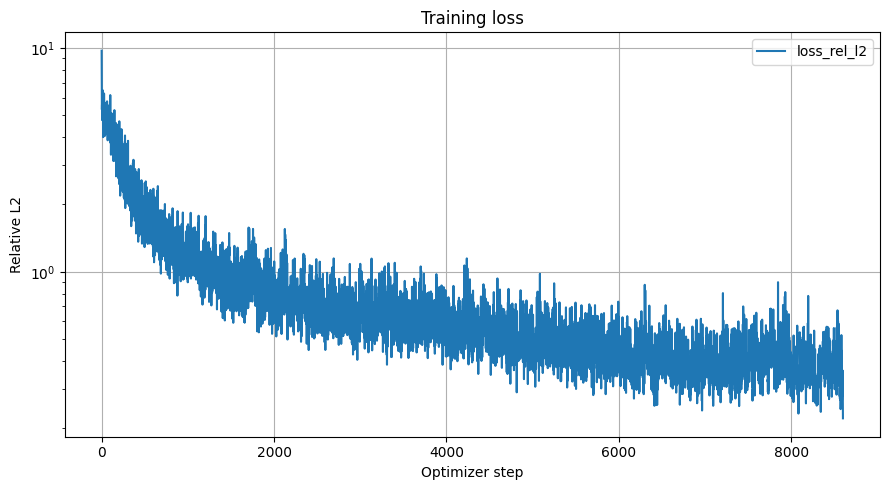

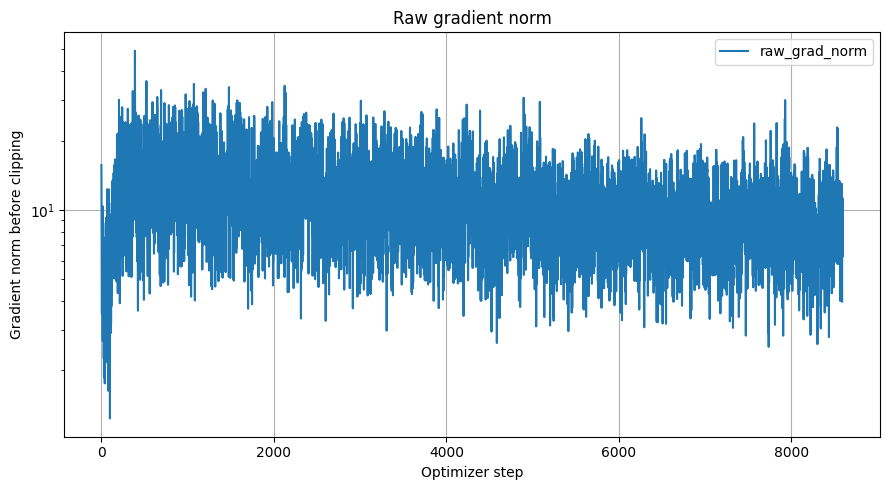

In [13]:
def plot_series(df, columns, ylabel, title, logy=False):
    if df is None or len(df) == 0:
        print("No data for:", title)
        return

    plt.figure(figsize=(9, 5))

    for col in columns:
        if col in df.columns:
            plt.plot(
                df["global_optimizer_step"],
                df[col],
                label=col,
            )

    plt.xlabel("Optimizer step")
    plt.ylabel(ylabel)
    plt.title(title)

    if logy:
        plt.yscale("log")

    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if len(step_log):
    step_df = pd.DataFrame(step_log)

    plot_series(
        step_df,
        ["loss_rel_l2"],
        "Relative L2",
        "Training loss",
        logy=True,
    )

    plot_series(
        step_df,
        ["raw_grad_norm"],
        "Gradient norm before clipping",
        "Raw gradient norm",
        logy=True,
    )



## 12. Gradients and parameter values

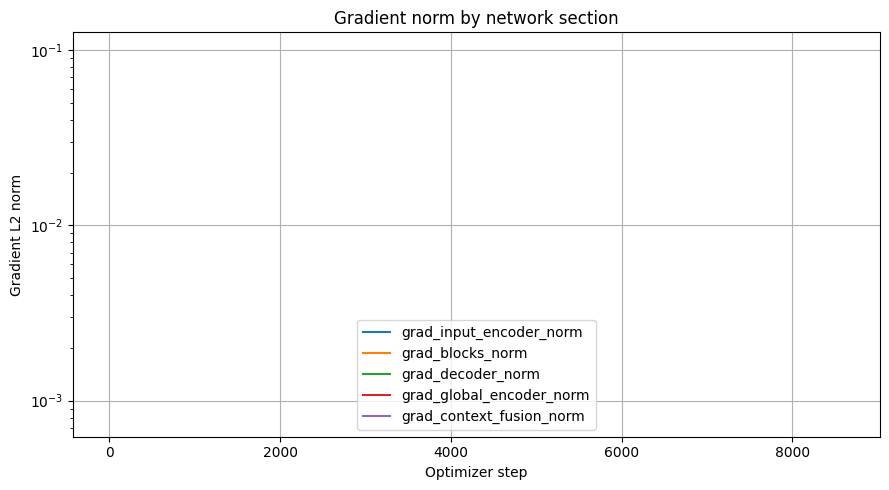

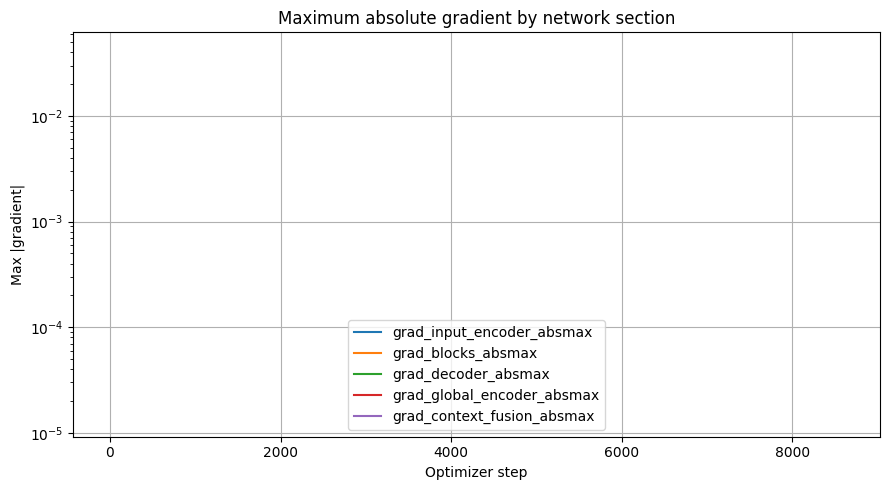

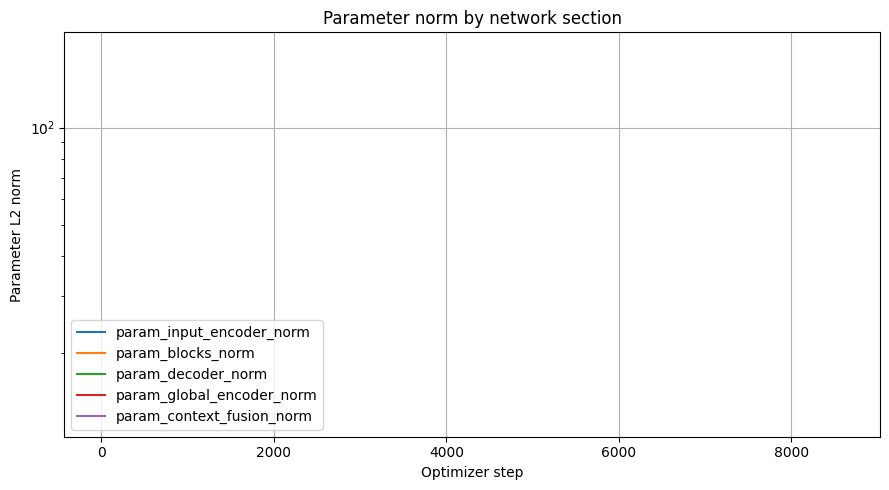

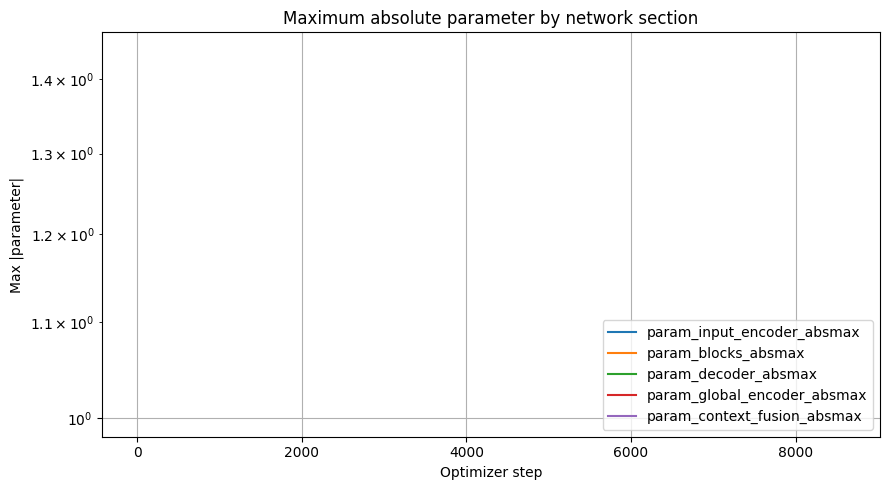

In [14]:
if len(step_log):
    for prefix, statistic, ylabel, title in (
        ("grad", "norm", "Gradient L2 norm", "Gradient norm by network section"),
        ("grad", "absmax", "Max |gradient|", "Maximum absolute gradient by network section"),
        ("param", "norm", "Parameter L2 norm", "Parameter norm by network section"),
        ("param", "absmax", "Max |parameter|", "Maximum absolute parameter by network section"),
    ):
        plot_series(step_df, [f"{prefix}_{group}_{statistic}" for group in parameter_group_map(model)],
                    ylabel, title, logy=True)


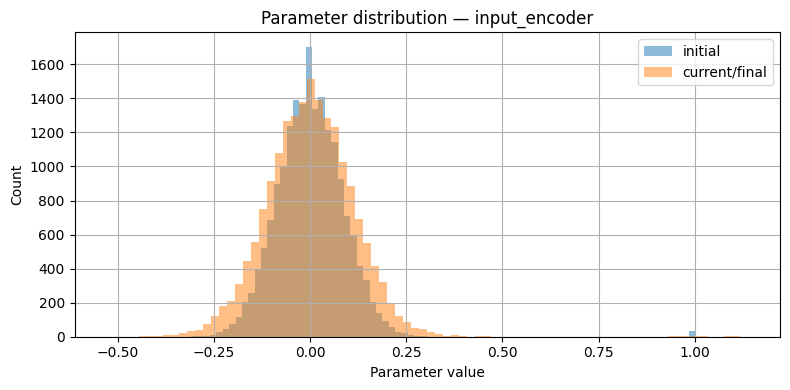

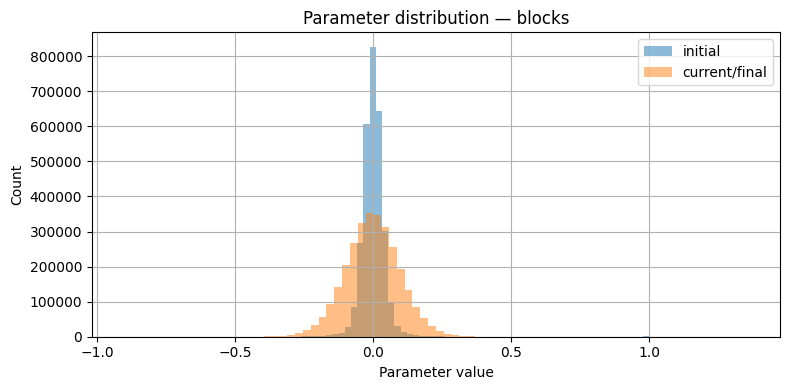

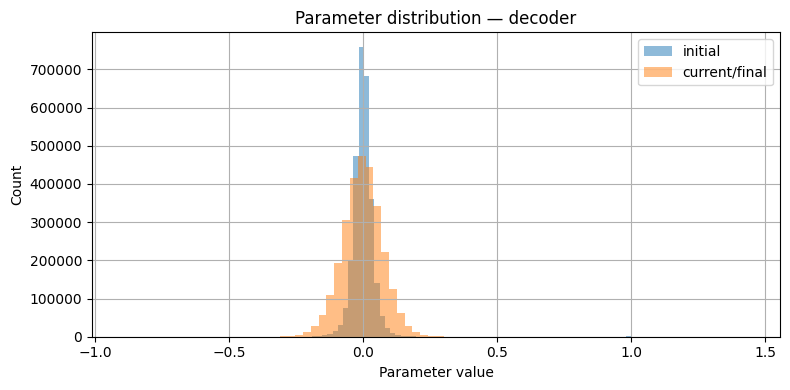

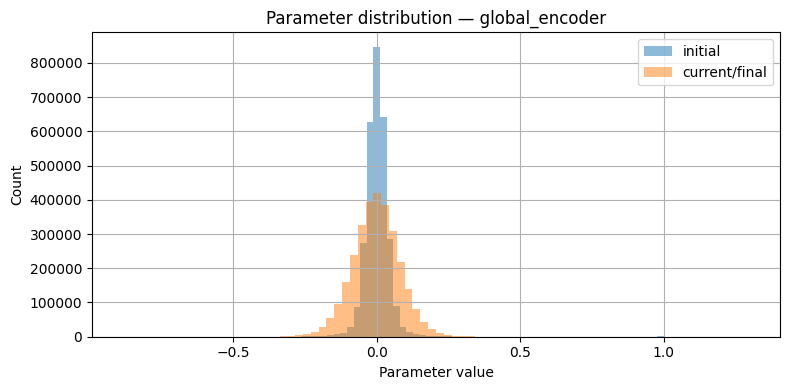

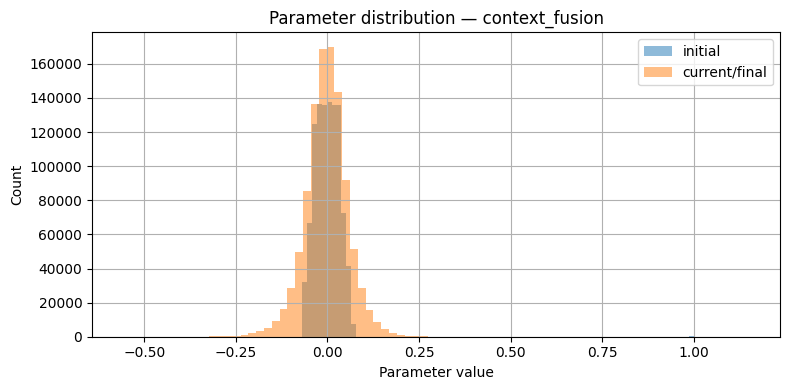

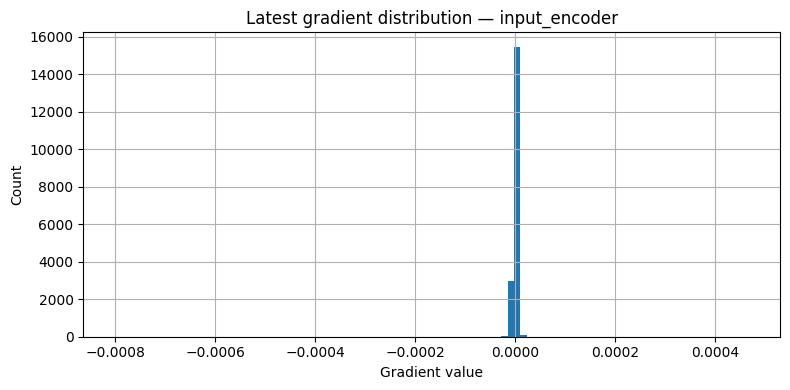

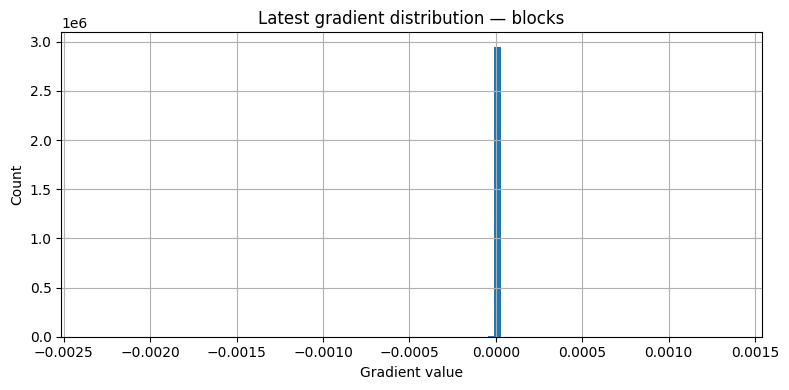

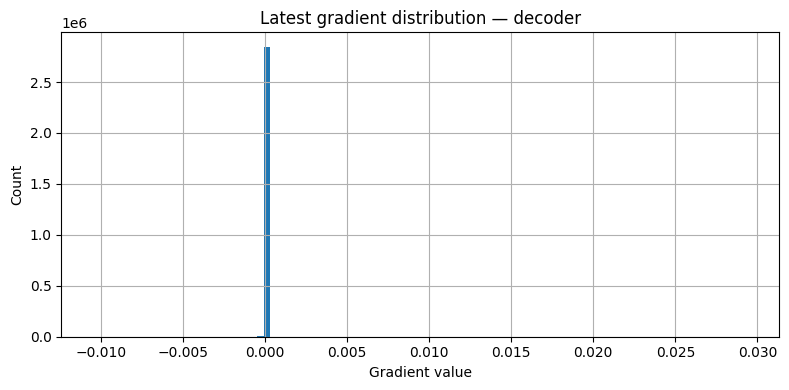

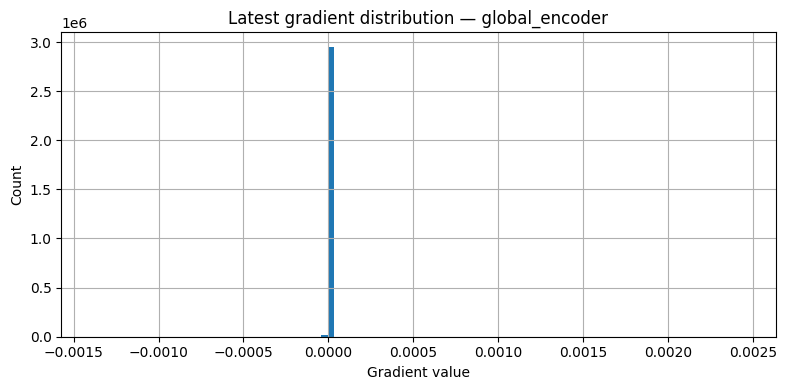

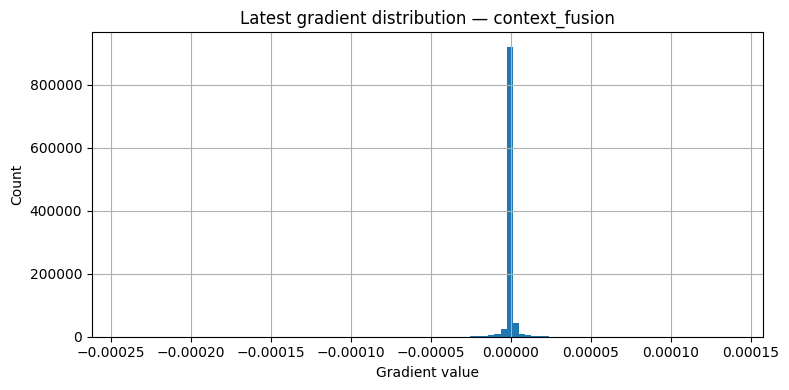

In [15]:
final_parameter_snapshot = snapshot_parameter_values(model)

for group_name, final_values in final_parameter_snapshot.items():
    initial_values = initial_parameter_snapshot.get(
        group_name,
        np.array([]),
    )

    plt.figure(figsize=(8, 4))

    if len(initial_values):
        plt.hist(
            initial_values,
            bins=80,
            alpha=0.5,
            label="initial",
        )

    if len(final_values):
        plt.hist(
            final_values,
            bins=80,
            alpha=0.5,
            label="current/final",
        )

    plt.xlabel("Parameter value")
    plt.ylabel("Count")
    plt.title(f"Parameter distribution — {group_name}")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


if last_gradient_snapshot is not None:
    for group_name, values in last_gradient_snapshot.items():
        if len(values) == 0:
            continue

        plt.figure(figsize=(8, 4))
        plt.hist(values, bins=100)
        plt.xlabel("Gradient value")
        plt.ylabel("Count")
        plt.title(f"Latest gradient distribution — {group_name}")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

## 13. Global encoder, local encoder and decoder internals


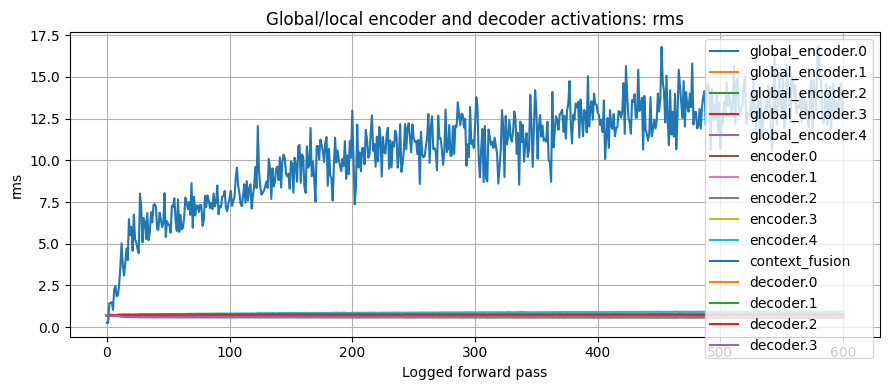

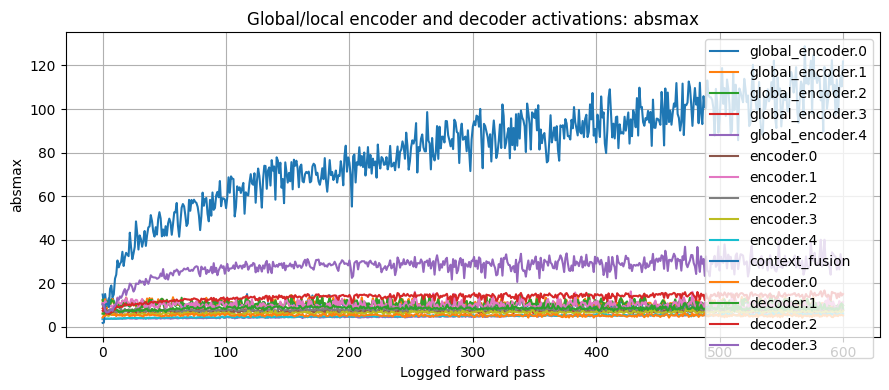

In [16]:
internal_df = recorder.dataframe()
if len(internal_df):
    tensor_df = internal_df[internal_df["kind"] == "tensor"].copy()
    for metric in ("rms", "absmax"):
        plt.figure(figsize=(9, 4))
        for tag in tensor_df["tag"].unique():
            d = tensor_df[tensor_df["tag"] == tag].reset_index(drop=True)
            plt.plot(np.arange(len(d)), d[metric], label=tag)
        plt.xlabel("Logged forward pass"); plt.ylabel(metric)
        plt.title("Global/local encoder and decoder activations: " + metric)
        plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    print("No detailed internal records.")


## 14. Layer output evolution

,epoch,batch,tag,mean,std,rms,absmax,norm
9000,200,40,global_encoder.0,0.355786,0.579016,0.679590,8.107656,1391.800781
9001,200,40,global_encoder.1,0.347826,0.596028,0.690096,9.767454,999.365601
9002,200,40,global_encoder.2,0.335726,0.599953,0.687500,9.868426,703.999756
9003,200,40,global_encoder.3,0.360561,0.620522,0.717671,7.438623,519.649597
9004,200,40,global_encoder.4,0.433656,0.734916,0.853322,5.562326,345.400574
9005,200,40,encoder.0,0.350791,0.466263,0.583486,7.795853,1194.978760
9006,200,40,encoder.1,0.312988,0.557162,0.639055,11.369349,925.450073
9007,200,40,encoder.2,0.337370,0.622433,0.707983,9.552748,724.975098
9008,200,40,encoder.3,0.387170,0.656775,0.762400,7.262976,552.036743
9009,200,40,encoder.4,0.515671,0.778029,0.933405,5.992501,377.815887


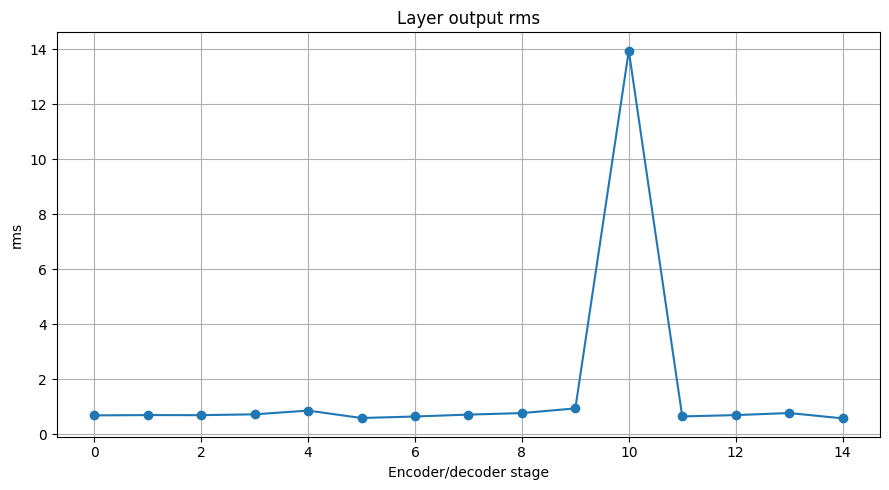

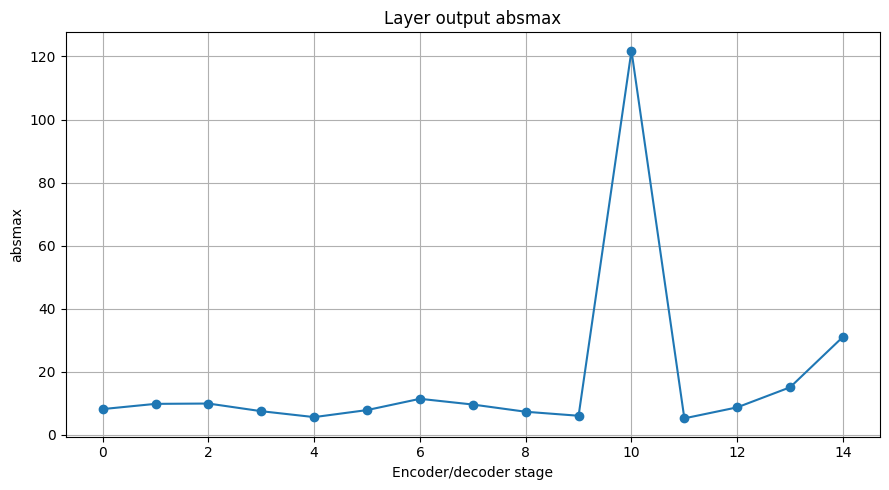

In [17]:
internal_df = recorder.dataframe()
tensor_df = internal_df[internal_df["kind"] == "tensor"].copy()
if len(tensor_df):
    latest_epoch = tensor_df["epoch"].max()
    d = tensor_df[tensor_df["epoch"] == latest_epoch]
    d = d[d["batch"] == d["batch"].max()]
    display(d[["epoch", "batch", "tag", "mean", "std", "rms", "absmax", "norm"]])
    for metric in ("rms", "absmax"):
        plt.figure(figsize=(9, 5))
        plt.plot(np.arange(len(d)), d[metric], marker="o")
        plt.xlabel("Encoder/decoder stage"); plt.ylabel(metric)
        plt.title("Layer output " + metric); plt.grid(True); plt.tight_layout(); plt.show()

## 15. Epoch curves

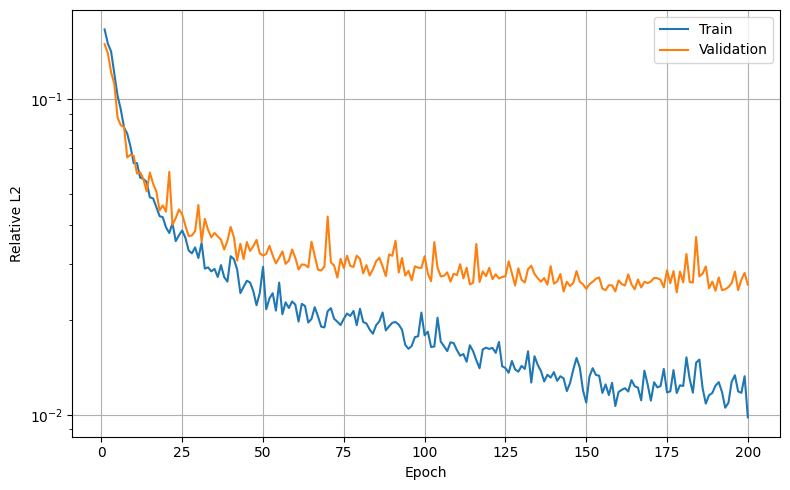

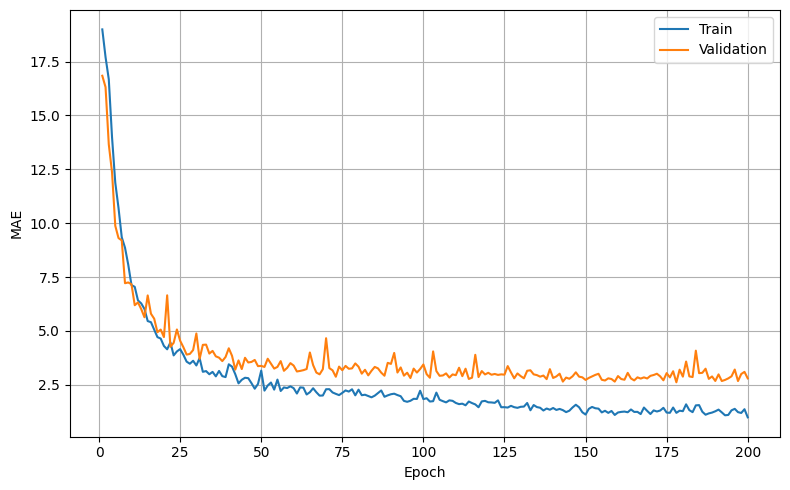

In [18]:
if len(history["train_rel_l2"]):
    e = np.arange(1, len(history["train_rel_l2"]) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_rel_l2"], label="Train")
    plt.plot(e, history["val_rel_l2"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Relative L2")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(e, history["train_mae"], label="Train")
    plt.plot(e, history["val_mae"], label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("MAE")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No complete epoch recorded.")

## 16. Interpretation

This comparison uses the same fixed matched 64x64 patches, pair-selection rules, geometry-held-out split, normalization, training loss, optimizer settings and metrics as patch_context_investigation.ipynb. The current source notebook uses 1,000 pairs and 200 epochs. No augmentation, random crops or benchmark testing is added. Training includes both original simulated targets in each pair; repeated simulation patches are deduplicated.

The model additionally receives a 64x64 AREA-AVERAGED representation of all eight full-board input channels: x, y, standardized power density, chip occupancy, ceramic, baseplate, copper and h/10000. This is a downsampled WHOLE 256x256 board, not another local patch. Power density is averaged rather than point-subsampled so small heat sources contribute to coarse cells. Material masks become area fractions. These coarse inputs contain no temperature values or simulation identifiers. The ROI consists only of the selected patch's normalized board boundaries.

Both residual encoders use channels [32,64,128,256,320], one two-convolution residual block per stage and independent weights. The local U-Net keeps its two-convolution decoder and native skip connections. The coarse encoder yields a 4x4x320 feature map. One residual self-attention block mixes all 16 coarse bottleneck tokens, followed by a residual feed-forward block. Only AFTER that global mixing do we bilinearly sample the requested region into a 4x4 feature grid. A 1x1 convolution fuses these context features with the local bottleneck. The local decoder predicts only a 1x64x64 temperature patch. There is no global decoder, coarse temperature supervision, full-board temperature prediction or second-stage pretraining. All components train together from the same patch loss.

The residual encoders and decoder are reused from the installed nnU-Net architecture package; the global feature fusion is our custom 2D regression model, NOT nnU-Net's built-in 3D segmentation cascade. Full-board context is processed before ROI sampling, so sampled features can depend on distant power changes. Local inputs remain identical within matched pairs, while global inputs differ. Predictions are now ALLOWED to differ. They are not forced to do so, and low training/validation error is an empirical question.

The pair manifest retains target-to-target RelL2 (A reference) and the local-only unavoidable-worst-case bound for comparison with the baseline. That bound does NOT constrain this global-context model. The final CSV labels it local_only_worst_case_bound and never asserts identical predictions or a lower bound on this model's error.

Epoch Mean/Max/Median/P90/P95/P99 describe dimensionless per-sample RelL2 on decoded temperature fields. MAE is in Celsius. Normalization uses only the same unique original training simulation fields. The official ValData/TestData benchmark remains unused. Detailed previews stay limited to inspect_pairs; every selected pair is included in final diagnostics.

Outputs use a separate patch_context_global_local_1000pairs directory, preserving the local-only runs. Checkpoints store the model class, construction settings, normalization, selected pairs, optimizer state and metric history. This experiment changes the input/model and requested channel widths together; comparisons against the wide local baseline therefore do not isolate context from width. Compare against the saved narrow residual run for matching encoder widths.

Sources: [nnU-Net](https://github.com/MIC-DKFZ/nnUNet), [dynamic-network-architectures](https://github.com/MIC-DKFZ/dynamic-network-architectures) and [Multi-topology Dataset](https://github.com/henkuailederen/Multi-topology-Dataset). The data are CC BY 4.0; cite Ruiting Ke, Jianfeng Tao and Chengliang Liu's accompanying study and Isensee et al., Nature Methods (2021), for nnU-Net.


## 17. Best checkpoint - compare both patch predictions and simulated targets


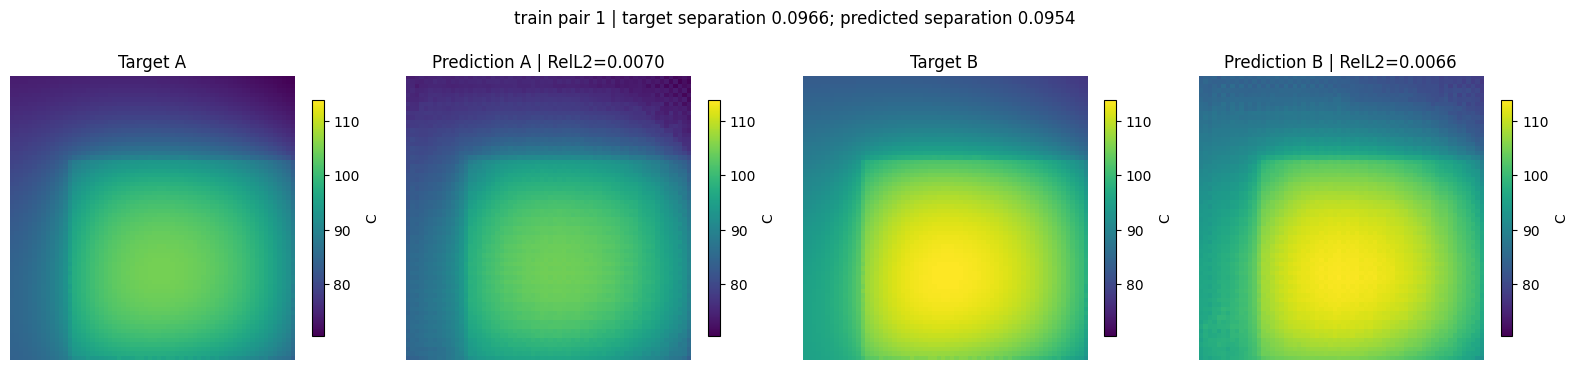

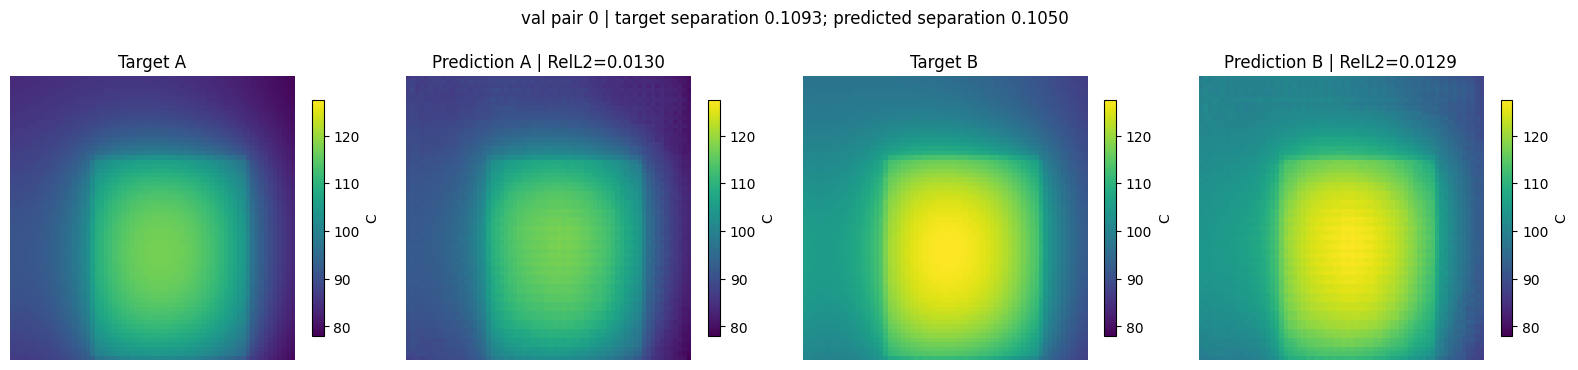

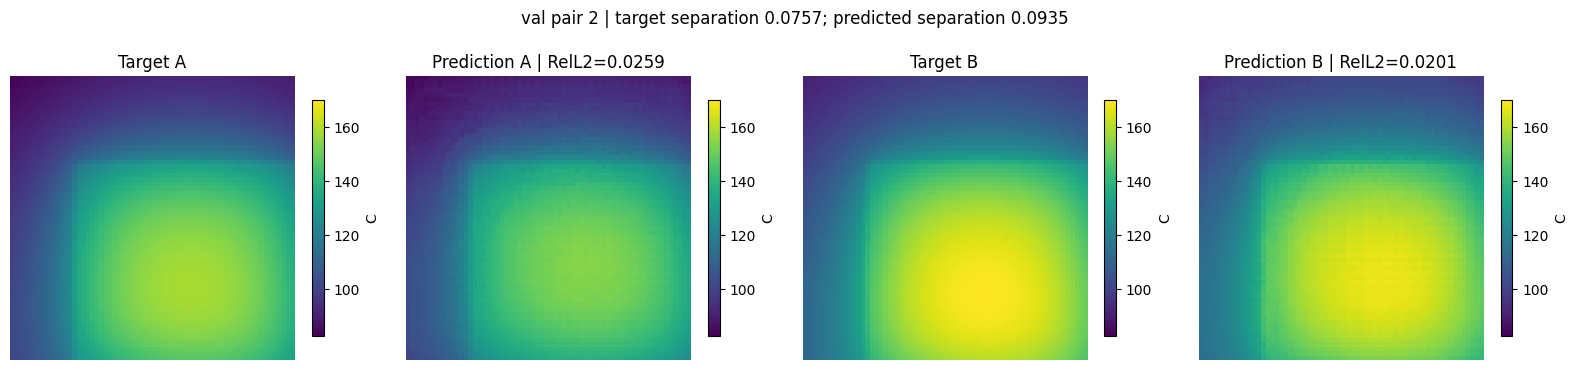

,pair_id,subset,rel_l2_a,rel_l2_b,worst_rel_l2,local_only_worst_case_bound,identical_local_inputs,identical_global_inputs,target_difference_rel_l2,prediction_difference_rel_l2_a_ref
0,1,train,0.006953,0.006551,0.006953,0.046085,True,False,0.096586,0.095424
1,3,train,0.007005,0.008372,0.008372,0.044576,True,False,0.093300,0.089768
2,4,train,0.012692,0.017078,0.017078,0.112080,True,False,0.252311,0.261910
3,5,train,0.006679,0.011732,0.011732,0.049132,True,False,0.103283,0.090999
4,6,train,0.014143,0.009370,0.014143,0.090163,True,False,0.197611,0.189161
...,...,...,...,...,...,...,...,...,...,...
995,972,val,0.016418,0.018595,0.018595,0.151763,True,False,0.357422,0.362792
996,980,val,0.044599,0.056745,0.056745,0.062606,True,False,0.133320,0.093825
997,992,val,0.036409,0.018186,0.036409,0.053853,True,False,0.113784,0.157264
998,995,val,0.108970,0.127224,0.127224,0.026405,True,False,0.054237,0.028407


Best epoch: 178
Checkpoint: pcb\outputs\patch_context_global_local_1000pairs\patch_context.pt
Held-out benchmark testing remains disabled.


In [19]:
checkpoint = torch.load(HPARAMS["checkpoint_path"], map_location=device, weights_only=True)
assert checkpoint["model_class"] == "GlobalContextNNUNetRegressor"
model.load_state_dict(checkpoint["model_state_dict"])
normalizer = NormalizationStats(**checkpoint["normalization"])
model.eval()
comparison_rows = []
for subset, dataset in (("train", train_dataset), ("val", val_dataset)):
    for index, record in enumerate(dataset.records):
        sample_a, sample_b = dataset.pair_indices[index]
        inputs_a, target_a_norm = dataset[sample_a]
        inputs_b, target_b_norm = dataset[sample_b]
        assert torch.equal(inputs_a["local"], inputs_b["local"])
        assert torch.equal(inputs_a["roi"], inputs_b["roi"])
        assert not torch.equal(inputs_a["global"], inputs_b["global"])
        batch_inputs = {key: torch.stack([inputs_a[key], inputs_b[key]]) for key in inputs_a}
        with torch.no_grad():
            predictions = normalizer.decode_temperature(predict_field(batch_inputs))
        targets = normalizer.decode_temperature(torch.stack([target_a_norm, target_b_norm]))
        errors = relative_l2_per_sample(predictions, targets)
        # Same reference for true/predicted pair separation; no model-error floor is asserted.
        prediction_difference = (torch.linalg.vector_norm(predictions[1] - predictions[0])
                                 / torch.linalg.vector_norm(targets[0])).item()
        comparison_rows.append(dict(
            pair_id=record["pair_id"], subset=subset,
            rel_l2_a=errors[0].item(), rel_l2_b=errors[1].item(), worst_rel_l2=errors.max().item(),
            local_only_worst_case_bound=record["unavoidable_worst_case_rel_l2"],
            identical_local_inputs=True, identical_global_inputs=False,
            target_difference_rel_l2=record["target_difference_rel_l2"],
            prediction_difference_rel_l2_a_ref=prediction_difference,
        ))
        if record["pair_id"] in preview_pair_ids:
            fig, axes = plt.subplots(1, 4, figsize=(16, 4))
            arrays = [targets[0, 0].numpy(), predictions[0, 0].numpy(),
                      targets[1, 0].numpy(), predictions[1, 0].numpy()]
            lo, hi = min(a.min() for a in arrays), max(a.max() for a in arrays)
            titles = ["Target A", f"Prediction A | RelL2={errors[0]:.4f}",
                      "Target B", f"Prediction B | RelL2={errors[1]:.4f}"]
            for ax, array, title in zip(axes, arrays, titles):
                im = ax.imshow(array, vmin=lo, vmax=hi); ax.set_title(title); ax.axis("off")
                fig.colorbar(im, ax=ax, shrink=.7, label="C")
            fig.suptitle(f"{subset} pair {record['pair_id']} | target separation "
                         f"{record['target_difference_rel_l2']:.4f}; predicted separation {prediction_difference:.4f}")
            fig.tight_layout(); fig.savefig(WORKING_DIR / f"prediction_pair_{record['pair_id']:02d}.png", dpi=130)
            plt.show(); plt.close(fig)
comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(WORKING_DIR / "paired_prediction_metrics.csv", index=False)
display(comparisons)
print("Best epoch:", checkpoint["epoch"])
print("Checkpoint:", HPARAMS["checkpoint_path"])
print("Held-out benchmark testing remains disabled.")
for handle in hook_handles:
    handle.remove()


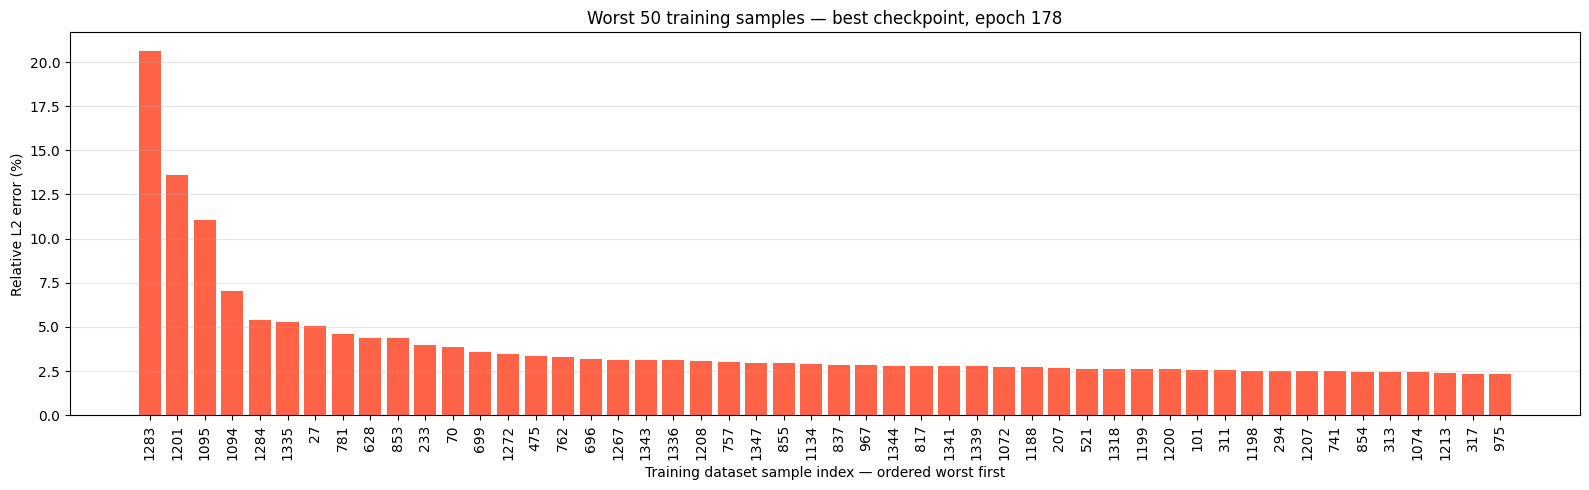

,sample_index,RelL2_percent,simulation_file
0,1283,20.649558,Surrogates/...
1,1201,13.613527,Surrogates/...
2,1095,11.044960,Surrogates/...
3,1094,7.012121,Surrogates/...
4,1284,5.414314,Surrogates/...
5,1335,5.264672,Surrogates/...
6,27,5.060751,Surrogates/...
7,781,4.608401,Surrogates/...
8,628,4.386915,Surrogates/...
9,853,4.344732,Surrogates/...


In [20]:
# Independent evaluation: does not change the training model or optimizer.
checkpoint_eval = torch.load(
    HPARAMS["checkpoint_path"], map_location="cpu", weights_only=True
)
model_eval = type(model)(**checkpoint_eval["model_kwargs"]).to(device)
model_eval.load_state_dict(checkpoint_eval["model_state_dict"])
model_eval.eval()
normalizer_eval = type(normalizer)(**checkpoint_eval["normalization"])

loader_eval = DataLoader(
    train_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,          # preserves dataset sample indices
    num_workers=0,
)

sample_errors = []
with torch.inference_mode():
    for inputs, target_norm in loader_eval:
        if isinstance(inputs, dict):
            inputs = {k: v.to(device) for k, v in inputs.items()}
        else:
            inputs = inputs.to(device)

        prediction = normalizer_eval.decode_temperature(
            model_eval(inputs).cpu()
        )
        target = normalizer_eval.decode_temperature(target_norm)
        sample_errors.extend(
            relative_l2_per_sample(prediction, target).tolist()
        )

sample_errors = np.asarray(sample_errors)
if not np.isfinite(sample_errors).all():
    raise ValueError("Nonfinite training-sample errors detected")

worst_indices = np.argsort(-sample_errors, kind="stable")[:50]
worst_errors_pct = 100 * sample_errors[worst_indices]

fig, ax = plt.subplots(figsize=(16, 5))
ax.bar(np.arange(len(worst_indices)), worst_errors_pct, color="tomato")
ax.set_xticks(np.arange(len(worst_indices)))
ax.set_xticklabels(worst_indices, rotation=90)
ax.set_xlabel("Training dataset sample index — ordered worst first")
ax.set_ylabel("Relative L2 error (%)")
ax.set_title(
    f"Worst {len(worst_indices)} training samples "
    f"— best checkpoint, epoch {checkpoint_eval['epoch']}"
)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

worst_train_samples = pd.DataFrame({
    "sample_index": worst_indices,
    "RelL2_percent": worst_errors_pct,
    "simulation_file": [
        str(train_dataset.files[int(i)]) for i in worst_indices
    ],
})
display(worst_train_samples)

del model_eval, checkpoint_eval


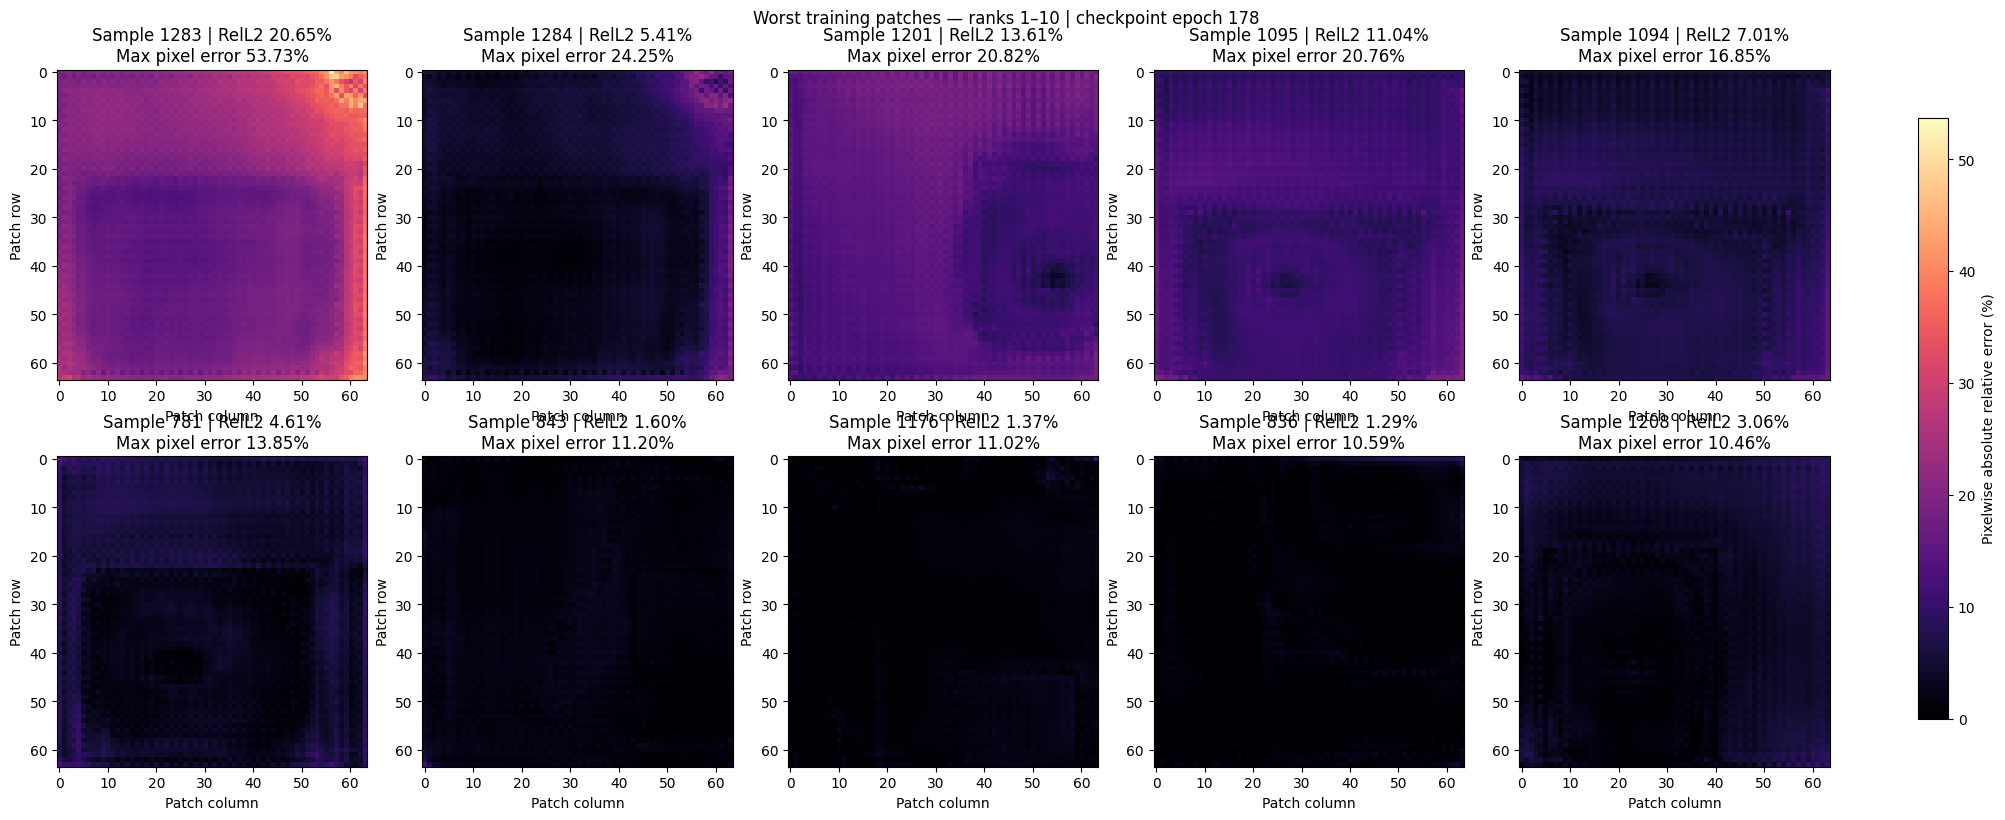

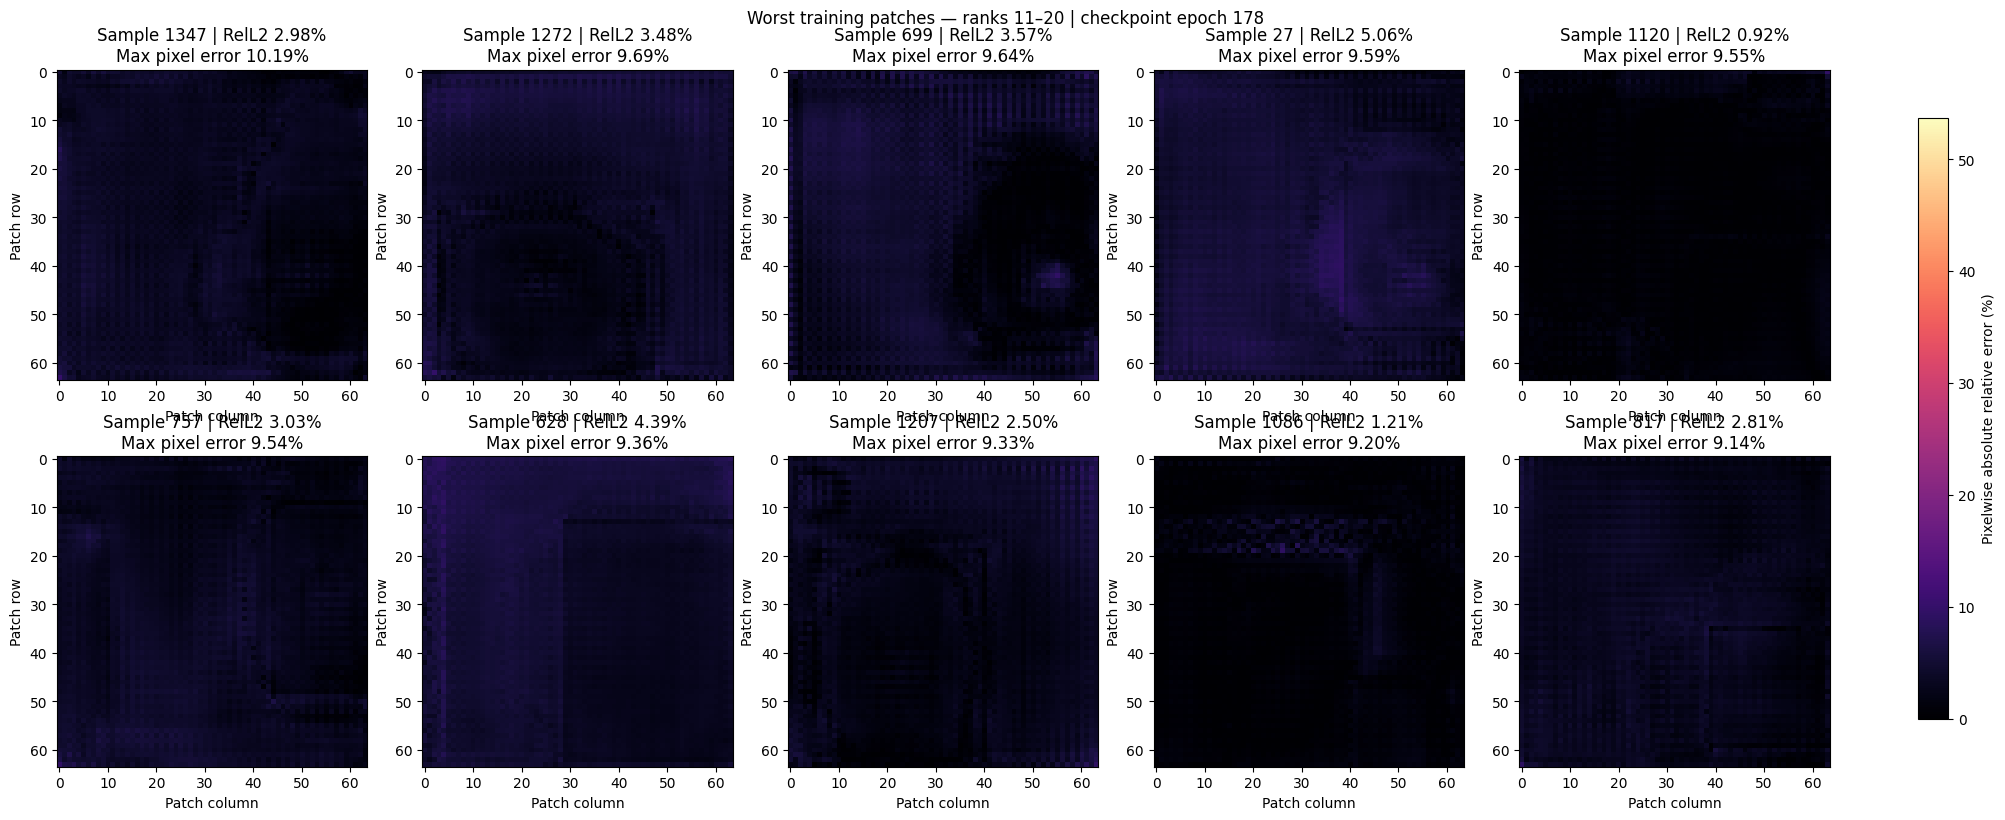

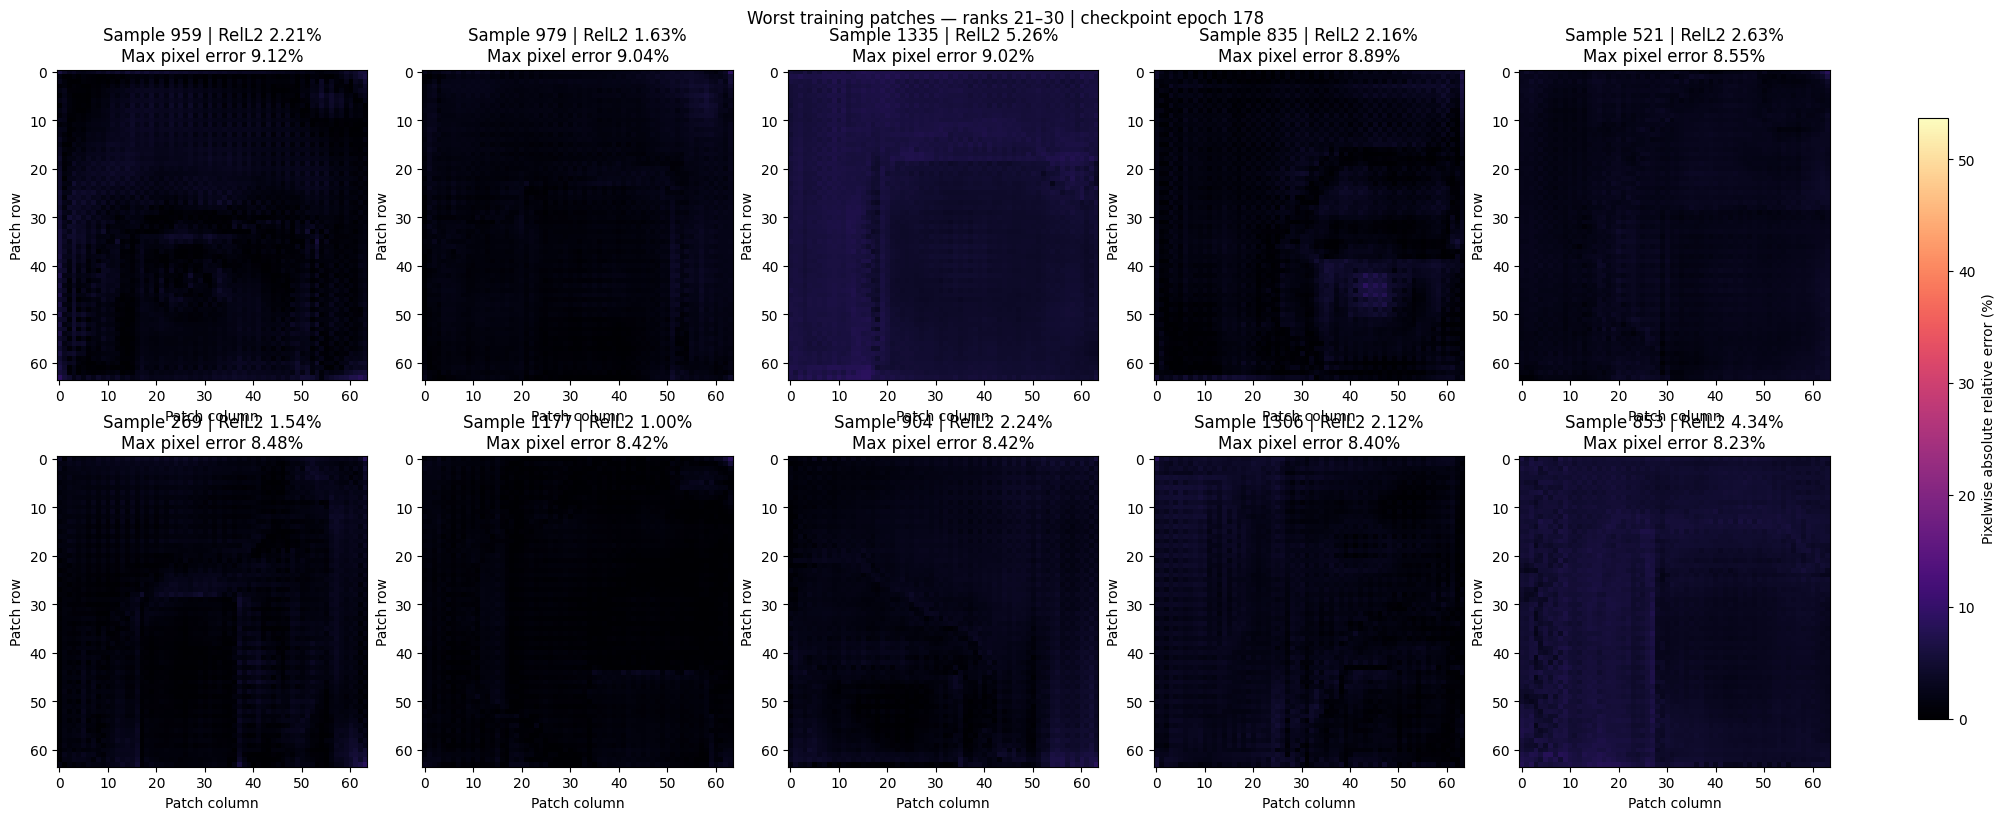

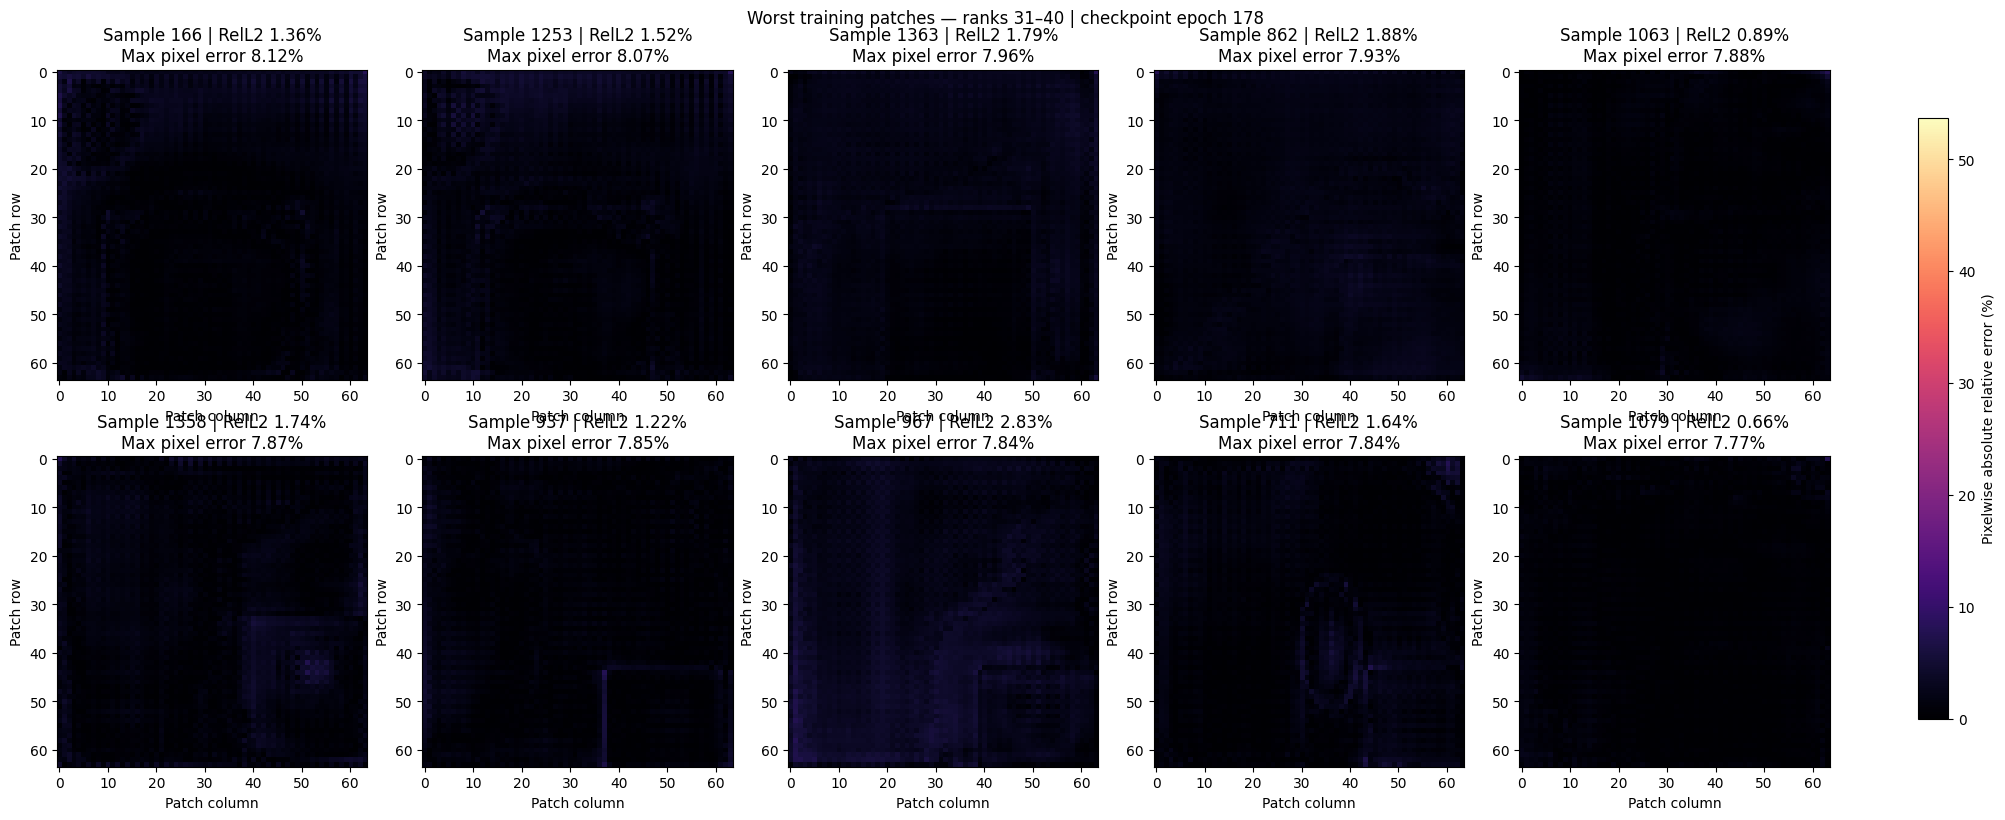

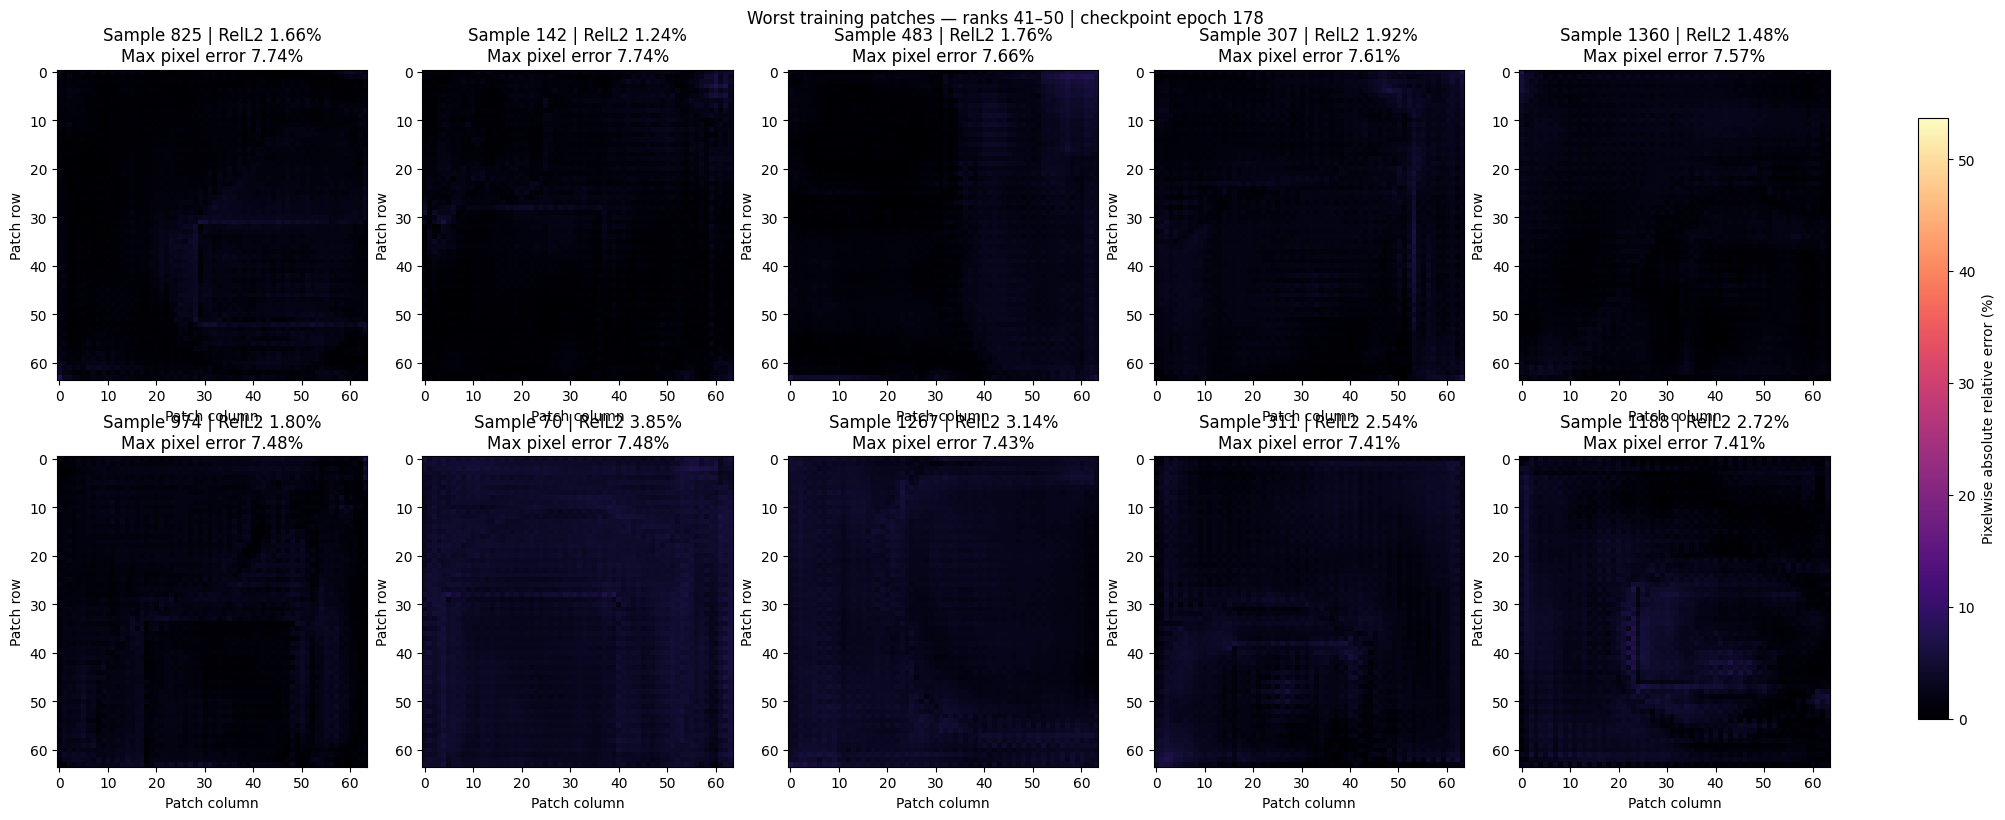

,sample_index,RelL2_percent,max_pixel_error_percent
0,1283,20.649558,53.728294
1,1284,5.414314,24.251028
2,1201,13.613527,20.820345
3,1095,11.044960,20.762417
4,1094,7.012121,16.852631
5,781,4.608401,13.845329
6,843,1.604591,11.196600
7,1176,1.372475,11.015291
8,836,1.288216,10.588773
9,1208,3.058603,10.456823


In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

N_WORST = 50
RANK_BY = "max_pixel_error_percent"  # alternatively: "RelL2_percent"
MAPS_PER_FIGURE = 10
ZERO_TOLERANCE = 1e-6  # near-zero target temperatures are masked

# Load the best checkpoint without modifying the training model.
cp_plot = torch.load(
    HPARAMS["checkpoint_path"], map_location="cpu", weights_only=True
)
model_plot = type(model)(**cp_plot["model_kwargs"]).to(device)
model_plot.load_state_dict(cp_plot["model_state_dict"])
model_plot.eval()
norm_plot = type(normalizer)(**cp_plot["normalization"])

loader_plot = DataLoader(
    train_dataset,
    batch_size=HPARAMS["batch_size"],
    shuffle=False,
    num_workers=0,
)

error_maps = []
rel_l2_values = []

with torch.inference_mode():
    for inputs, target_norm in loader_plot:
        if isinstance(inputs, dict):
            inputs = {k: v.to(device) for k, v in inputs.items()}
        else:
            inputs = inputs.to(device)

        prediction = norm_plot.decode_temperature(model_plot(inputs).cpu())
        target = norm_plot.decode_temperature(target_norm)

        if not torch.isfinite(prediction).all():
            raise ValueError("Nonfinite predictions detected")

        rel_l2_values.extend(
            relative_l2_per_sample(prediction, target).tolist()
        )

        denominator = target.abs()
        pixel_error = 100 * (prediction - target).abs() / denominator.clamp_min(
            ZERO_TOLERANCE
        )
        pixel_error = pixel_error.masked_fill(
            denominator <= ZERO_TOLERANCE, float("nan")
        )
        error_maps.extend(pixel_error[:, 0].numpy())

error_maps = np.stack(error_maps)
if not np.isfinite(error_maps).reshape(len(error_maps), -1).any(axis=1).all():
    raise ValueError("A patch has no defined pixelwise relative errors")

error_table = pd.DataFrame({
    "sample_index": np.arange(len(error_maps)),
    "RelL2_percent": 100 * np.asarray(rel_l2_values),
    "max_pixel_error_percent": np.nanmax(error_maps, axis=(1, 2)),
})

worst_train_pixels = (
    error_table.sort_values(RANK_BY, ascending=False, kind="stable")
    .head(N_WORST)
    .reset_index(drop=True)
)
selected_indices = worst_train_pixels["sample_index"].to_numpy()

# Identical color scale across all selected patches; no clipping.
color_max = max(float(np.nanmax(error_maps[selected_indices])), 1e-6)
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("lightgray")

for start in range(0, len(selected_indices), MAPS_PER_FIGURE):
    page = worst_train_pixels.iloc[start:start + MAPS_PER_FIGURE]
    fig, axes = plt.subplots(
        2, 5, figsize=(20, 8), layout="constrained"
    )

    for ax, (_, row) in zip(axes.flat, page.iterrows()):
        index = int(row["sample_index"])
        im = ax.imshow(
            error_maps[index],
            cmap=cmap,
            vmin=0,
            vmax=color_max,
            interpolation="nearest",
        )
        ax.set_title(
            f"Sample {index} | RelL2 {row['RelL2_percent']:.2f}%\n"
            f"Max pixel error {row['max_pixel_error_percent']:.2f}%"
        )
        ax.set_xlabel("Patch column")
        ax.set_ylabel("Patch row")

    for ax in list(axes.flat)[len(page):]:
        ax.set_visible(False)

    fig.colorbar(
        im, ax=list(axes.flat), shrink=0.85,
        label="Pixelwise absolute relative error (%)",
    )
    fig.suptitle(
        f"Worst training patches — ranks {start + 1}–{start + len(page)}"
        f" | checkpoint epoch {cp_plot['epoch']}"
    )
    plt.show()
    plt.close(fig)

display(worst_train_pixels)

del model_plot, cp_plot

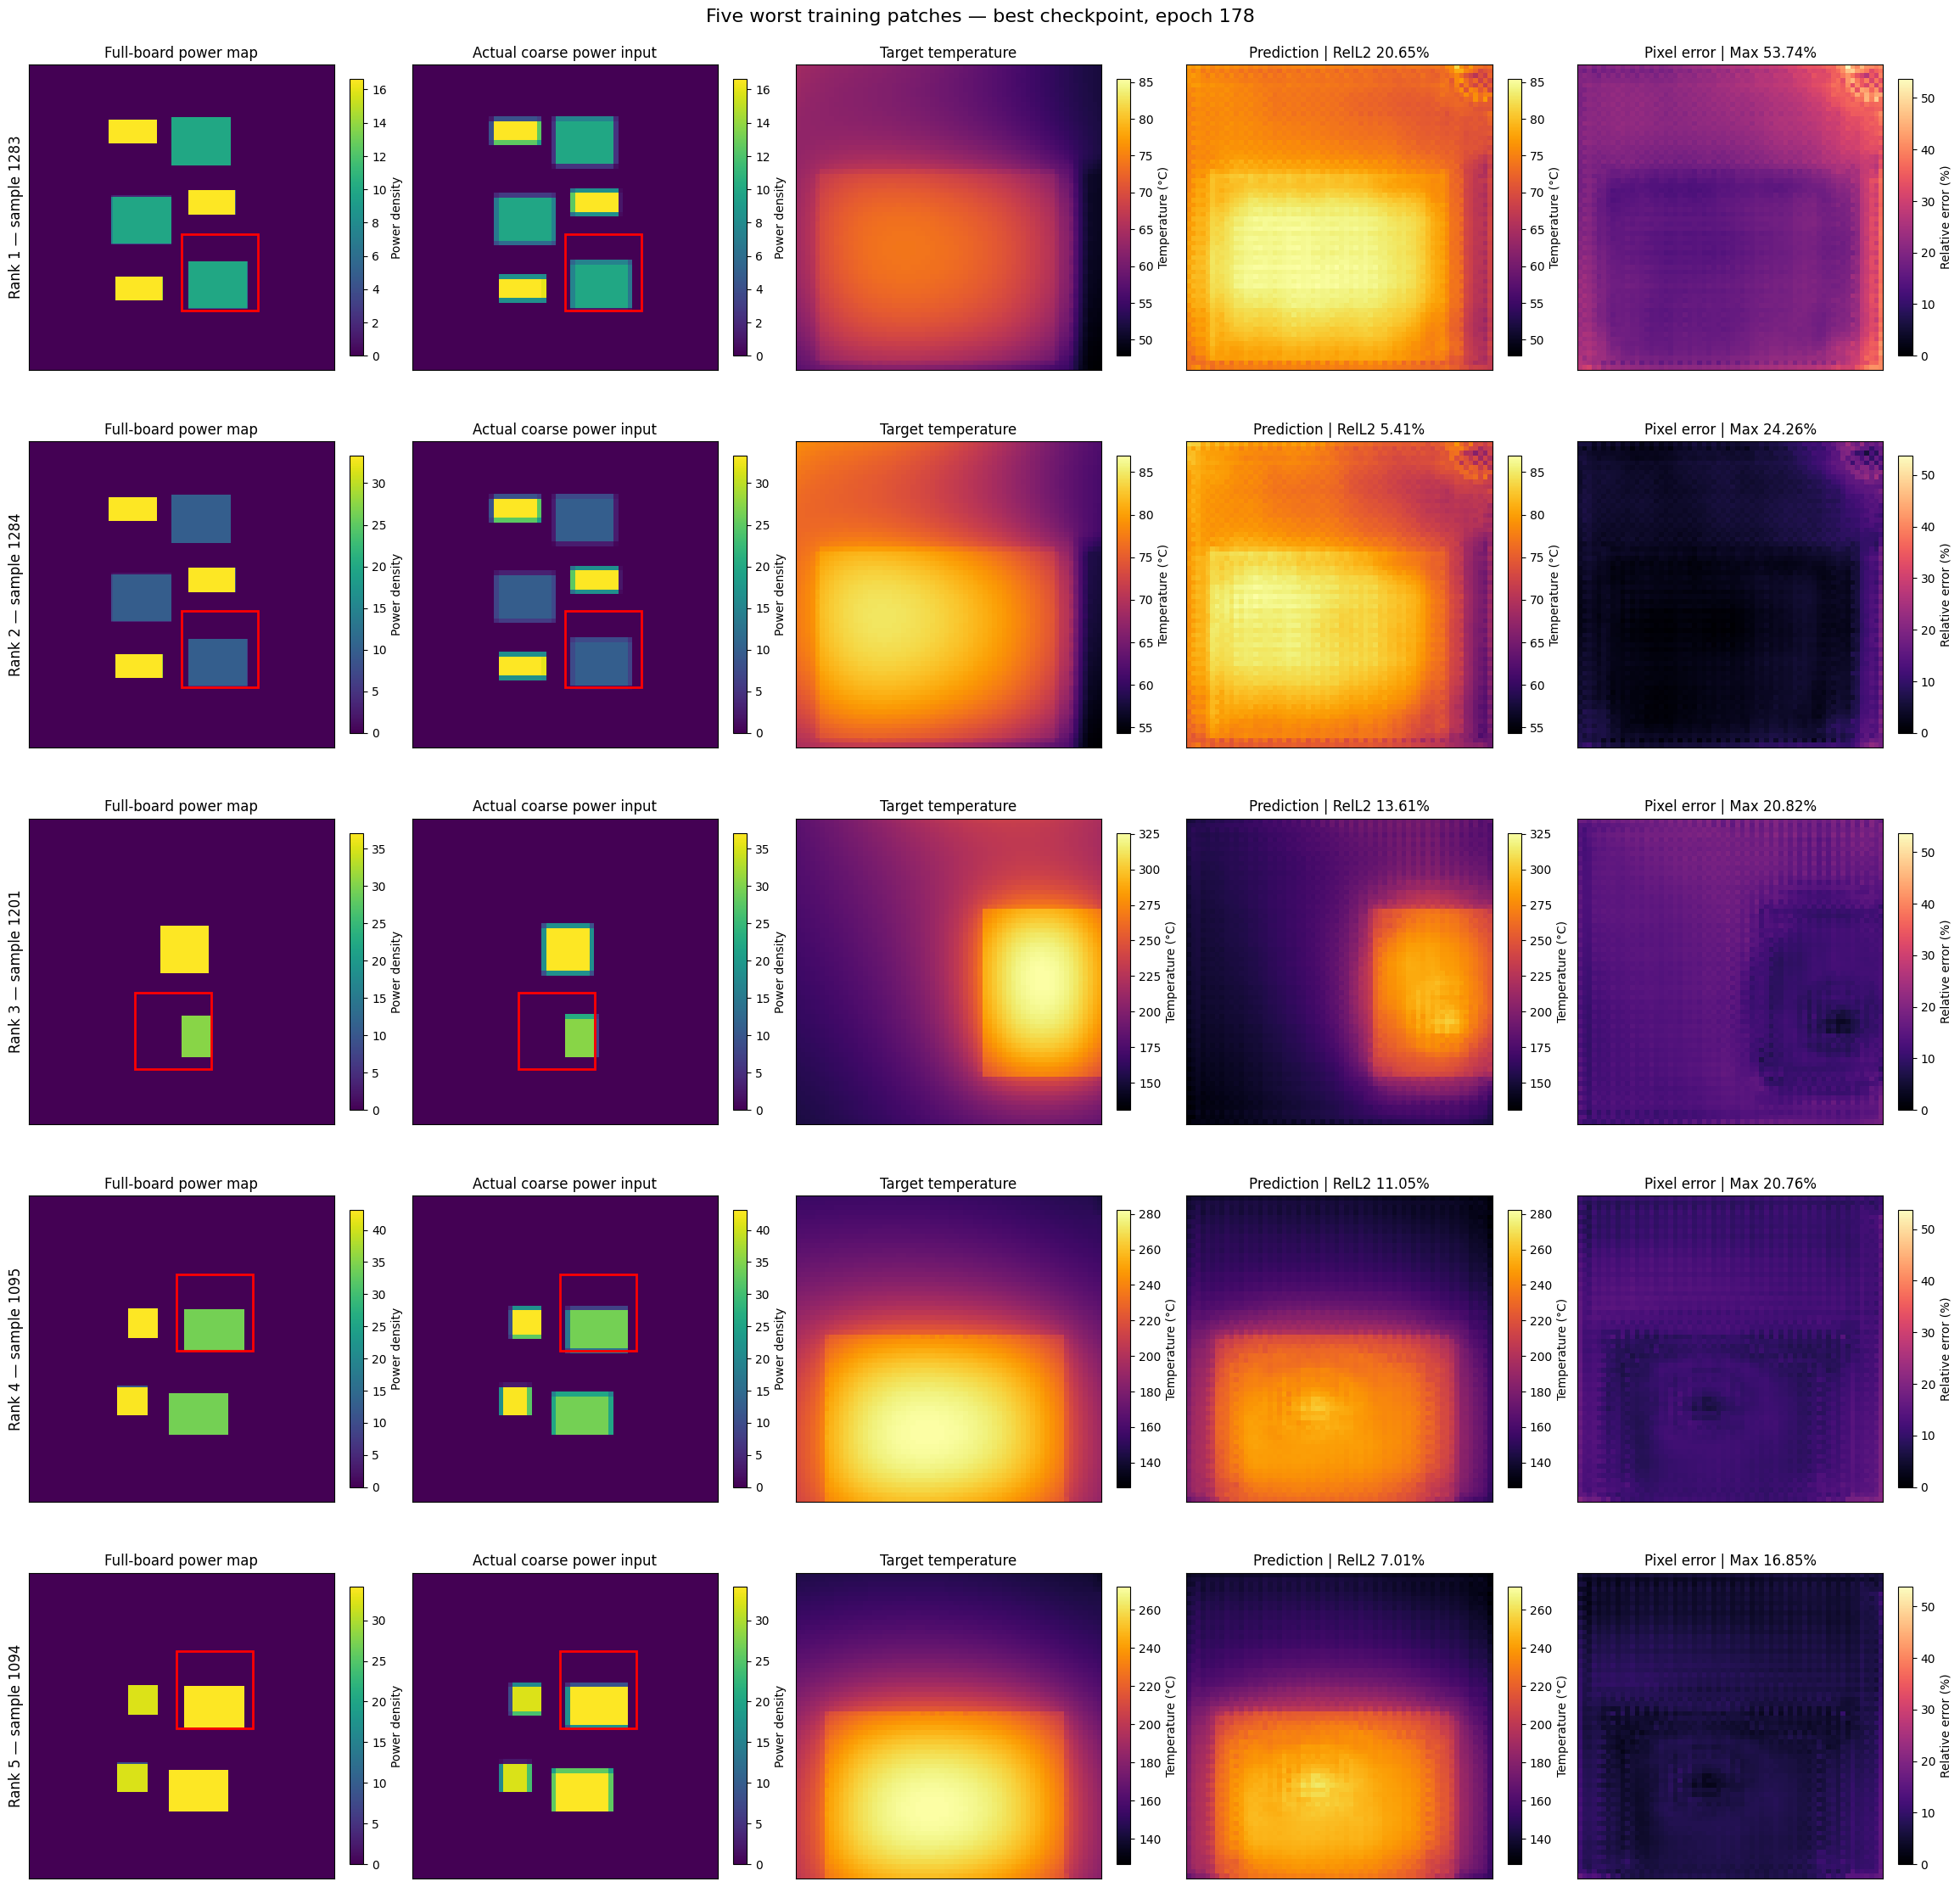

In [22]:
from matplotlib.patches import Rectangle

top5 = worst_train_pixels.head(5)
cp_5 = torch.load(
    HPARAMS["checkpoint_path"], map_location="cpu", weights_only=True
)
model_5 = type(model)(**cp_5["model_kwargs"]).to(device)
model_5.load_state_dict(cp_5["model_state_dict"])
model_5.eval()
norm_5 = type(normalizer)(**cp_5["normalization"])

# Map unique dataset samples back to their patch coordinates.
sample_records = {
    sample_index: record
    for record, indices in zip(train_dataset.records, train_dataset.pair_indices)
    for sample_index in indices
}

panels = []
with torch.inference_mode():
    for index in top5["sample_index"].astype(int):
        inputs, target_norm = train_dataset[index]
        batch = {key: value.unsqueeze(0).to(device)
                 for key, value in inputs.items()}

        prediction = norm_5.decode_temperature(model_5(batch).cpu())[0, 0]
        target = norm_5.decode_temperature(target_norm)[0]

        pixel_error = 100 * (prediction - target).abs() / target.abs().clamp_min(1e-6)
        pixel_error[target.abs() <= 1e-6] = float("nan")

        case = read_case(str(train_dataset.files[index]))
        coarse_power = (
            inputs["global"][2] * norm_5.power_std + norm_5.power_mean
        ).numpy()

        rel_l2 = (
            torch.linalg.vector_norm(prediction - target)
            / torch.linalg.vector_norm(target)
        ).item()

        panels.append({
            "index": index,
            "record": sample_records[index],
            "board": case["power_map"],
            "coarse": coarse_power,
            "roi": inputs["roi"].numpy(),
            "target": target.numpy(),
            "prediction": prediction.numpy(),
            "error": pixel_error.numpy(),
            "rel_l2": rel_l2,
        })

error_max = max(float(np.nanmax(p["error"])) for p in panels)
error_max = max(error_max, 1e-6)

fig, axes = plt.subplots(
    len(panels), 5, figsize=(23, 4.5 * len(panels)),
    squeeze=False, layout="constrained",
)

for row, p in enumerate(panels):
    r = p["record"]
    power_max = max(float(p["board"].max()), 1e-6)
    temperature_min = min(p["target"].min(), p["prediction"].min())
    temperature_max = max(p["target"].max(), p["prediction"].max())

    arrays = [
        p["board"], p["coarse"], p["target"], p["prediction"], p["error"]
    ]
    titles = [
        "Full-board power map",
        "Actual coarse power input",
        "Target temperature",
        f"Prediction | RelL2 {100*p['rel_l2']:.2f}%",
        f"Pixel error | Max {np.nanmax(p['error']):.2f}%",
    ]

    for col, (array, title) in enumerate(zip(arrays, titles)):
        ax = axes[row, col]
        if col < 2:
            options = dict(cmap="viridis", vmin=0, vmax=power_max)
            units = "Power density"
        elif col < 4:
            options = dict(cmap="inferno", vmin=temperature_min, vmax=temperature_max)
            units = "Temperature (°C)"
        else:
            options = dict(cmap="magma", vmin=0, vmax=error_max)
            units = "Relative error (%)"

        im = ax.imshow(array, interpolation="nearest", **options)
        ax.set_title(title)
        ax.set_xticks([])
        ax.set_yticks([])
        fig.colorbar(im, ax=ax, shrink=0.75, label=units)

    # Native-board patch position.
    axes[row, 0].add_patch(Rectangle(
        (r["column"] - 0.5, r["row"] - 0.5),
        r["patch_size"], r["patch_size"],
        fill=False, edgecolor="red", linewidth=2,
    ))

    # Corresponding region on the whole-board coarse input.
    left, top, right, bottom = p["roi"]
    height, width = p["coarse"].shape
    axes[row, 1].add_patch(Rectangle(
        (left * width - 0.5, top * height - 0.5),
        (right - left) * width, (bottom - top) * height,
        fill=False, edgecolor="red", linewidth=2,
    ))
    axes[row, 0].set_ylabel(
        f"Rank {row + 1} — sample {p['index']}", fontsize=12
    )

fig.suptitle(
    f"Five worst training patches — best checkpoint, epoch {cp_5['epoch']}",
    fontsize=16,
)
plt.show()
plt.close(fig)

del model_5, cp_5